# Detecting Intended and Perceived Deception in Diplomacy Negotiations

**Module 771767: Applied AI (002_CWRK) Jupyter notebook**

Dataset: Peskov, D., Cheng, B., Elgohary, A., Barrow, J., Danescu-Niculescu-Mizil, C.,
& Boyd-Graber, J. (2020). *It Takes Two to Lie: One to Lie, and One to Listen.* ACL.

Section numbers below correspond to the section numbers of the written report.

> **Reproducibility.** All data is downloaded automatically in Section 0; no local files
> or external modules are required. Run all cells top to bottom.
>
> **Provenance.** Every figure in the Section 10 results tables is computed from model
> predictions and appended to a single `RESULTS` list by one function, `record_result()`.
> The only hand-entered numbers are the published figures of Peskov et al. (2020), used
> for dataset verification and literature comparison, and labelled as such where they appear.
>
> **Environment.** Python 3.9.6, scikit-learn 1.6.1, PyTorch 2.8.0, transformers 4.57.6,
> pandas 2.3.3, matplotlib 3.8. Minor version changes may shift deep-learning figures slightly.

## 0. Setup

In [1]:
# Standard library
import json
import random
import sys
import urllib.request
from pathlib import Path
from typing import Optional
import pandas as pd
import torch
import transformers 

# Third-party
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.metrics import f1_score, precision_score, recall_score


RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

print(f"python       {sys.version.split()[0]}")
print(f"numpy        {np.__version__}")
print(f"pandas       {pd.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"torch  {torch.__version__}")
print(f"transformers {transformers.__version__}")

/Users/michellebuchiokonicha/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


python       3.9.6
numpy        1.26.4
pandas       2.3.3
scikit-learn 1.6.1
torch  2.8.0
transformers 4.57.6


In [2]:
# checking the available device
torch.manual_seed(RANDOM_STATE)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")      
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"device {DEVICE}")

device mps


### 0.1 Download the data

The dataset is fetched directly from the authors' repository so this notebook is
reproducible on any machine without manual setup.

In [3]:
# Data gotten directly from github for easy reproducibility and to prevent system overload
DATA_URL = "https://raw.githubusercontent.com/DenisPeskoff/2020_acl_diplomacy/master/data"
DATA_DIR = Path("data")
SPLITS = ("train", "validation", "test")

EXPECTED_BYTES = {"train": 2_472_563, "validation": 245_870, "test": 490_273}

#fetching the JSONL splits
def download_data(data_dir: Path = DATA_DIR, base_url: str = DATA_URL) -> None:
    """Fetch the three JSONL splits from the authors' repository if not already present.

    Byte sizes are asserted so that a truncated or substituted file fails loudly here
    rather than producing subtly wrong numbers downstream.
    """
    data_dir.mkdir(exist_ok=True)
    for split in SPLITS:
        target = data_dir / f"{split}.jsonl"
        if not target.exists():
            urllib.request.urlretrieve(f"{base_url}/{split}.jsonl", target)
            print(f"  downloaded {target}")
        size = target.stat().st_size
        assert size == EXPECTED_BYTES[split], (
            f"{target} is {size:,} bytes, expected {EXPECTED_BYTES[split]:,}"
        )
        print(f"  {target}  {size:>10,} bytes  OK")


download_data()

  data/train.jsonl   2,472,563 bytes  OK
  data/validation.jsonl     245,870 bytes  OK
  data/test.jsonl     490,273 bytes  OK


## 5. Dataset

### 5.1 Structure of the raw files

Each line of the JSONL files is a **dyadic conversation**, the complete message history
between one *pair* of players, not a full game. Seven players per game gives
C(7,2) = 21 dyads per game, which is why the files hold 189 / 21 / 42 lines for the
9 / 1 / 2 games in each split.

The schema is inspected directly rather than taken from the repository's `README.md`,
which documents one field under the wrong name (`score_delta`; the actual key is
`game_score_delta`).

In [4]:
def inspect_schema(path: Path) -> pd.DataFrame:
    """Report every key of a JSONL record with its type and length.

    Separates per-message parallel lists from conversation-level scalars. A `length`
    equal to the message count identifies a per-message field.
    """
    with open(path, encoding="utf-8") as fh:
        record = json.loads(fh.readline())
    n_msgs = len(record["messages"])
    rows = [{
        "field": k,
        "type": type(v).__name__,
        "length": len(v) if isinstance(v, list) else "scalar",
        "per_message": isinstance(v, list) and len(v) == n_msgs,
        "example": repr(v[0])[:34] if isinstance(v, list) else repr(v)[:34],
    } for k, v in record.items()]
    return pd.DataFrame(rows)


inspect_schema(DATA_DIR / "train.jsonl")

,field,type,length,per_message,example
0,messages,list,321,True,'Germany!\n\nJust the person I wan
1,sender_labels,list,321,True,True
2,receiver_labels,list,321,True,True
3,speakers,list,321,True,'italy'
4,receivers,list,321,True,'germany'
5,absolute_message_index,list,321,True,74
6,relative_message_index,list,321,True,0
7,seasons,list,321,True,'Spring'
8,years,list,321,True,'1901'
9,game_score,list,321,True,'3'


### 5.2 Label polarity

The most important thing to know about this dataset is that **the boolean labels are
inverted relative to the task**. In `sender_labels` and `receiver_labels`:

| raw value | meaning |
|---|---|
| `True` | the message is **truthful** |
| `False` | the message is a **lie** |

Taking `int(label)` directly would therefore encode *truth* as 1. Since the lie is the
minority class and the class of interest, it is encoded as the positive class (1) here,
which is the convention assumed by precision, recall, F1 and average precision. The
assertion below fixes this against the count published by Peskov et al. (591 lies in
train) so the polarity can never silently flip.

In [5]:
# Verify polarity against the published count before writing any loader that depends on it.
_sender = [v for line in open(DATA_DIR / "train.jsonl", encoding="utf-8")
             for v in json.loads(line)["sender_labels"]]

n_true, n_false = _sender.count(True), _sender.count(False)
print(f"raw sender_labels == True : {n_true:>6,}")
print(f"raw sender_labels == False: {n_false:>6,}")
print(f"\nPeskov et al. report 591 ACTUAL LIES in train.")
assert n_false == 591, "polarity check failed: False should be the 591 lies"
print("=> False == Lie, True == Truth. Lies will be encoded as 1.")

raw sender_labels == True : 12,541
raw sender_labels == False:    591

Peskov et al. report 591 ACTUAL LIES in train.
=> False == Lie, True == Truth. Lies will be encoded as 1.


### 5.3 Loading and structuring

In [6]:
# Per-message parallel lists. `players` (length 2) and `game_id` (scalar) are
# conversation-level and are attached separately.
MESSAGE_LEVEL_FIELDS = [
    "messages", "sender_labels", "receiver_labels", "speakers", "receivers",
    "absolute_message_index", "relative_message_index", "seasons", "years",
    "game_score", "game_score_delta",
]


def load_split(path: Path, split_name: str) -> pd.DataFrame:
    """Explode one JSONL file from conversation-level to message-level rows.

    Retains `game_id` and a `dyad_id` built from the player pair, so that the
    game-level train/validation/test boundary is respected by anything downstream.
    """
    records = []
    with open(path, encoding="utf-8") as fh:
        for line in fh:
            convo = json.loads(line)
            players = "|".join(sorted(convo["players"]))
            for i in range(len(convo["messages"])):
                # Singularise field names: "messages" -> "message"
                row = {f[:-1] if f.endswith("s") else f: convo[f][i]
                       for f in MESSAGE_LEVEL_FIELDS}
                row.update(
                    split=split_name,
                    game_id=convo["game_id"],
                    # A dyad is a player pair within a game. Identifying it by what it
                    # is, rather than by line position, is stable under reordering.
                    dyad_id=f"g{convo['game_id']}_{players}",
                    dyad_players=players,
                )
                records.append(row)
    return pd.DataFrame.from_records(records)


def load_all(data_dir: Path = DATA_DIR) -> pd.DataFrame:
    """Load all three splits into one message-level DataFrame."""
    return pd.concat([load_split(data_dir / f"{s}.jsonl", s) for s in SPLITS],
                     ignore_index=True)

### 5.4 Deriving the two target variables

The dataset supports two distinct prediction tasks that share the same input text:

| task | label source | question | missingness |
|---|---|---|---|
| `actual_lie` | the **sender**, at composition time | *Did the sender intend to deceive?* | none |
| `suspected_lie` | the **receiver**, on reading | *Did the receiver perceive deception?* | `"NOANNOTATION"` |

Two decisions carried into the report:

1. **The lie is the positive class (1)** for both tasks, per Section 5.2.
2. **Unannotated receiver labels become `NaN`, never `0`.** Coercing a missing
   annotation to "perceived truthful" would fabricate roughly 9% of the majority class
   and inflate apparent performance on `suspected_lie`. Those rows are dropped for that
   task only; `actual_lie` retains them because its labels are complete.

In [7]:
def add_task_labels(df: pd.DataFrame) -> pd.DataFrame:
    """Derive both binary targets. Positive class (1) = lie, for both tasks.

    Rows lacking a receiver annotation are NaN in `suspected_lie`, not 0.
    """
    df = df.copy()

    # False == Lie (verified in 5.2), so the lie becomes 1.
    df["actual_lie"] = (~df["sender_label"].astype(bool)).astype(int)

    df["suspected_lie"] = [
        np.nan if r == "NOANNOTATION" else float(r is False)
        for r in df["receiver_label"]
    ]
    df["receiver_annotated"] = df["suspected_lie"].notna()
    df["n_words"] = df["message"].str.split().str.len()
    df["n_chars"] = df["message"].str.len()
    return df





def task_frame(df: pd.DataFrame, task: str, split: Optional[str] = None) -> pd.DataFrame:
    """Rows usable for a task, with a unified `y` target column.

    task="actual"    -> all rows (labels complete)
    task="suspected" -> only rows carrying a receiver annotation

    This single accessor is what allows every model below to be written once and
    run against both tasks.
    """
    if task == "actual":
        out = df.copy()
        out["y"] = out["actual_lie"].astype(int)
    elif task == "suspected":
        out = df[df["receiver_annotated"]].copy()
        out["y"] = out["suspected_lie"].astype(int)
    else:
        raise ValueError(f"task must be 'actual' or 'suspected', got {task!r}")
    if split is not None:
        out = out[out["split"] == split].copy()
    return out


TASKS = ("actual", "suspected")

df = add_task_labels(load_all())
print(f"{len(df):,} messages | {df.game_id.nunique()} games | {df.dyad_id.nunique()} dyads\n")
df[["split", "game_id", "dyad_id", "speaker", "receiver", "message",
    "actual_lie", "suspected_lie"]].head()

17,289 messages | 12 games | 246 dyads



,split,game_id,dyad_id,speaker,receiver,message,actual_lie,suspected_lie
0,train,1,g1_germany|italy,italy,germany,Germany!\n\nJust the person I want to speak wi...,0,0.0
1,train,1,g1_germany|italy,germany,italy,"You've whet my appetite, Italy. What's the sug...",0,0.0
2,train,1,g1_germany|italy,italy,germany,👍,0,0.0
3,train,1,g1_germany|italy,germany,italy,It seems like there are a lot of ways that cou...,0,0.0
4,train,1,g1_germany|italy,italy,germany,"Yeah, I can’t say I’ve tried it and it works, ...",0,NaN


### 5.5 Integrity check against the published description

Every summary statistic is checked against the values reported by Peskov et al. before
any modelling. Showing that this pipeline reproduces their
description is what makes the comparison in Section 10 meaningful.

In [8]:
# Values reported in Peskov et al. (2020), Table 2 / Section 4.1.
PAPER_CLAIMS = {
    "total_messages": 17289,
    "train_messages": 13132,
    "train_actual_lies": 591,
    "train_suspected_lies": 566,
    "train_mean_words": 20.79,
    "train_games": 9,
    "validation_games": 1,
    "test_games": 2,
    # 252 conversation records exist, but six contain zero messages (see 5.5.1),
    # so only 246 dyads survive into a message-level frame.
    "total_dyads": 246,
    "conversation_records": 252,
    "silent_dyads": 6,
}


def verify(df: pd.DataFrame) -> pd.DataFrame:
    """Check loaded data against the values published in the source paper."""
    train = df[df.split == "train"]
    observed = {
        "total_messages": len(df),
        "train_messages": len(train),
        "train_actual_lies": int(train.actual_lie.sum()),
        "train_suspected_lies": int(train.suspected_lie.sum()),
        "train_mean_words": round(train.n_words.mean(), 2),
        "train_games": train.game_id.nunique(),
        "validation_games": df[df.split == "validation"].game_id.nunique(),
        "test_games": df[df.split == "test"].game_id.nunique(),
        "total_dyads": df.dyad_id.nunique(),
        "conversation_records": sum(
            sum(1 for _ in open(DATA_DIR / f"{s}.jsonl", encoding="utf-8")) for s in SPLITS
        ),
        "silent_dyads": sum(
            1 for s in SPLITS
            for line in open(DATA_DIR / f"{s}.jsonl", encoding="utf-8")
            if len(json.loads(line)["messages"]) == 0
        ),
    }
    return pd.DataFrame([
        {"check": k, "paper": PAPER_CLAIMS[k], "observed": v, "match": PAPER_CLAIMS[k] == v}
        for k, v in observed.items()
    ])


verification = verify(df)
assert verification.match.all(), f"data does not match publication:\n{verification}"
print("All checks passed.\n")
verification

All checks passed.



,check,paper,observed,match
0,total_messages,17289.00,17289.00,True
1,train_messages,13132.00,13132.00,True
2,train_actual_lies,591.00,591.00,True
3,train_suspected_lies,566.00,566.00,True
4,train_mean_words,20.79,20.79,True
5,train_games,9.00,9.00,True
6,validation_games,1.00,1.00,True
7,test_games,2.00,2.00,True
8,total_dyads,246.00,246.00,True
9,conversation_records,252.00,252.00,True


#### 5.5.1 Six silent dyads

The files hold 252 conversation records, 21 per game, one for every possible pair of
the seven players, but **six of those records contain no messages at all**. Those pairs
never communicated during their game. The records exist but hold nothing, so a
message-level frame contains 246 dyads, not 252.

This matters for two reasons. Any per-dyad aggregation must treat a silent dyad as
*absent* rather than as a zero, or it will bias dyad-level averages toward whichever
quantity is being summed. And it is a substantive observation about the game itself:
refusing to negotiate is a strategic choice, but one this dataset cannot represent,
because a message-level corpus can only record deception that was actually spoken.

In [9]:
# the silent dyads added to a dataframe
silent = [
    {"split": s, "game_id": json.loads(line)["game_id"],
     "players": "|".join(sorted(json.loads(line)["players"]))}
    for s in SPLITS
    for line in open(DATA_DIR / f"{s}.jsonl", encoding="utf-8")
    if len(json.loads(line)["messages"]) == 0
]
pd.DataFrame(silent)

,split,game_id,players
0,train,1,germany|turkey
1,train,3,france|turkey
2,train,6,england|italy
3,train,6,austria|england
4,train,10,france|turkey
5,validation,11,england|turkey


### 5.6 Class balance and distribution shift

Prevalence of the positive class is reported per split for both tasks. The test split
carries roughly twice the lie rate of the training split, a property that constrains
metric choice in Section 10.

In [10]:
def class_balance(df: pd.DataFrame) -> pd.DataFrame:
    """Positive-class rate per split for both tasks, plus missing-annotation counts."""
    rows = []
    for split in SPLITS:
        sub = df[df.split == split]
        ann = sub[sub.receiver_annotated]
        rows.append({
            "split": split,
            "games": sub.game_id.nunique(),
            "n_messages": len(sub),
            "actual_lies": int(sub.actual_lie.sum()),
            "actual_lie_%": round(100 * sub.actual_lie.mean(), 2),
            "no_annotation": int((~sub.receiver_annotated).sum()),
            "no_annotation_%": round(100 * (~sub.receiver_annotated).mean(), 2),
            "n_suspected_usable": len(ann),
            "suspected_lies": int(ann.suspected_lie.sum()),
            "suspected_lie_%": round(100 * ann.suspected_lie.mean(), 2),
        })
    return pd.DataFrame(rows)


balance = class_balance(df)
balance

,split,games,n_messages,actual_lies,actual_lie_%,no_annotation,no_annotation_%,n_suspected_usable,suspected_lies,suspected_lie_%
0,train,9,13132,591,4.50,1107,8.43,12025,566,4.71
1,validation,1,1416,56,3.95,133,9.39,1283,47,3.66
2,test,2,2741,240,8.76,266,9.70,2475,165,6.67


In [11]:
def per_game_lie_rate(df: pd.DataFrame) -> pd.DataFrame:
    """Lie rate per game, evidence for why a game-level split shifts prevalence."""
    g = (df.groupby(["split", "game_id"])
           .agg(n_messages=("actual_lie", "size"), lies=("actual_lie", "sum"))
           .reset_index())
    g["lie_rate_%"] = (100 * g.lies / g.n_messages).round(2)
    return g.sort_values(["split", "game_id"]).reset_index(drop=True)


game_rates = per_game_lie_rate(df)
print(f"lie rate ranges from {game_rates['lie_rate_%'].min()}% to "
      f"{game_rates['lie_rate_%'].max()}% across the 12 games")
game_rates

lie rate ranges from 2.35% to 12.48% across the 12 games


,split,game_id,n_messages,lies,lie_rate_%
0,test,4,1546,193,12.48
1,test,12,1195,47,3.93
2,train,1,2618,219,8.37
3,train,2,3302,78,2.36
4,train,3,1914,45,2.35
5,train,5,427,41,9.60
6,train,6,521,50,9.60
7,train,7,1003,45,4.49
8,train,8,905,27,2.98
9,train,9,1611,56,3.48


### 5.7 The deception ontology

Sender intent and receiver perception cross to give four outcomes. Reproducing this
contingency motivates treating the two label sets as **distinct prediction targets**
rather than noisy views of one signal.

In [12]:
def quadrants(df: pd.DataFrame, split: str = "train") -> pd.DataFrame:
    """Sender-intent x receiver-perception contingency (Peskov et al.'s ontology)."""
    sub = df[(df.split == split) & df.receiver_annotated]
    names = {(0, 0): "Straightforward", (0, 1): "Cassandra",
             (1, 0): "Deceived", (1, 1): "Caught"}
    counts = (sub.groupby(["actual_lie", "suspected_lie"]).size()
                 .rename("n").reset_index())
    counts["quadrant"] = [names[(int(a), int(s))]
                          for a, s in zip(counts.actual_lie, counts.suspected_lie)]
    counts["pct"] = (100 * counts.n / counts.n.sum()).round(2)
    return (counts[["quadrant", "actual_lie", "suspected_lie", "n", "pct"]]
            .sort_values("n", ascending=False).reset_index(drop=True))


quad = quadrants(df)
display(quad)

caught = int(quad.loc[quad.quadrant == "Caught", "n"].iloc[0])
cassandra = int(quad.loc[quad.quadrant == "Cassandra", "n"].iloc[0])
flagged = caught + cassandra
print(f"\nReceivers flagged {flagged} messages as lies; {caught} actually were "
      f"({100 * caught / flagged:.1f}% precision).")
print(f"That is {cassandra / caught:.1f}x more false accusations than correct catches.")

,quadrant,actual_lie,suspected_lie,n,pct
0,Straightforward,0,0.0,10979,91.30
1,Cassandra,0,1.0,501,4.17
2,Deceived,1,0.0,480,3.99
3,Caught,1,1.0,65,0.54



Receivers flagged 566 messages as lies; 65 actually were (11.5% precision).
That is 7.7x more false accusations than correct catches.


### 5.8 Human baseline

Treating each receiver's perception as a prediction of the sender's true intent yields a
human baseline for the `actual_lie` task, and reproduces the figure published by
Peskov et al.

In [13]:
def human_baseline(df: pd.DataFrame) -> pd.DataFrame:
    """Score receiver perception as a classifier predicting sender intent."""
    rows = []
    for split in SPLITS:
        sub = df[(df.split == split) & df.receiver_annotated]
        rows.append({
            "split": split,
            "lie_rate_%": round(100 * sub.actual_lie.mean(), 2),
            "precision": round(100 * precision_score(sub.actual_lie, sub.suspected_lie), 2),
            "recall": round(100 * recall_score(sub.actual_lie, sub.suspected_lie), 2),
            "lie_F1": round(100 * f1_score(sub.actual_lie, sub.suspected_lie), 2),
            "macro_F1": round(100 * f1_score(sub.actual_lie, sub.suspected_lie,
                                             average="macro"), 2),
        })
    return pd.DataFrame(rows)


HUMAN = human_baseline(df)
display(HUMAN)

print("\nPeskov et al. report a human baseline of 22.5 Lie F1 on the test split.")
print(f"Reproduced here: {HUMAN.loc[HUMAN.split=='test','lie_F1'].iloc[0]} on test, "
      f"but {HUMAN.loc[HUMAN.split=='train','lie_F1'].iloc[0]} on train and "
      f"{HUMAN.loc[HUMAN.split=='validation','lie_F1'].iloc[0]} on validation.")
print("Annotators do not differ across splits; minority-class F1 is prevalence-sensitive")
print("and the test games are unusually lie-dense. The published 22.5 is therefore")
print("partly an artefact of which games fell into the test split.")

,split,lie_rate_%,precision,recall,lie_F1,macro_F1
0,train,4.53,11.48,11.93,11.70,53.71
1,validation,3.90,8.51,8.00,8.25,52.32
2,test,8.36,25.45,20.29,22.58,58.14



Peskov et al. report a human baseline of 22.5 Lie F1 on the test split.
Reproduced here: 22.58 on test, but 11.7 on train and 8.25 on validation.
Annotators do not differ across splits; minority-class F1 is prevalence-sensitive
and the test games are unusually lie-dense. The published 22.5 is therefore
partly an artefact of which games fell into the test split.


## 6. Exploratory Data Analysis

### 6.1 Preprocessing

Preprocessing is deliberately minimal. Deception cues in this register are carried by
function words as well as hedges and politeness markers, exactly the tokens that aggressive
cleaning removes. Stop words are therefore **retained** and only structural
normalisation is applied.

In [14]:
import re

URL_RE = re.compile(r"https?://\S+|www\.\S+")
WS_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Minimal normalisation: strip URLs, collapse whitespace, lowercase.

    Stop words and punctuation are retained: hedges ("maybe", "I think") and
    politeness markers are function words, and prior work identifies them as
    linguistic harbingers of betrayal in this game.
    """
    text = URL_RE.sub(" URL ", str(text))
    text = WS_RE.sub(" ", text)
    return text.strip().lower()


df["clean_text"] = df["message"].apply(clean_text)

print(f"empty after cleaning: {(df.clean_text.str.len() == 0).sum()}")
print(f"median words: {df.n_words.median():.0f} | mean: {df.n_words.mean():.2f} | "
      f"95th pct: {df.n_words.quantile(0.95):.0f} | max: {df.n_words.max()}")
df[["message", "clean_text", "actual_lie", "suspected_lie"]].head(3)

empty after cleaning: 0
median words: 14 | mean: 20.35 | 95th pct: 60 | max: 294


,message,clean_text,actual_lie,suspected_lie
0,Germany!\n\nJust the person I want to speak wi...,germany! just the person i want to speak with....,0,0.0
1,"You've whet my appetite, Italy. What's the sug...","you've whet my appetite, italy. what's the sug...",0,0.0
2,👍,👍,0,0.0


### 6.2 Visualisation 1: class distribution across both tasks

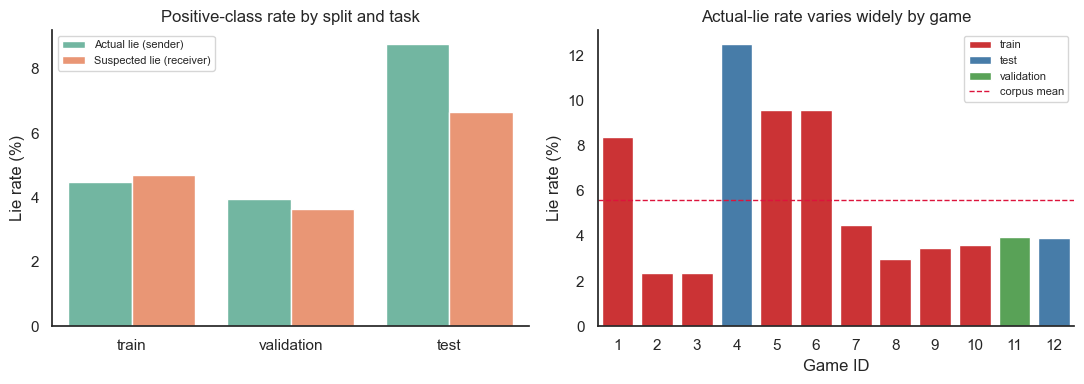

In [15]:
# Visualisation 1: positive-class rate by split and per game (imbalance and train/test shift)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

plot_df = balance.melt(id_vars="split", value_vars=["actual_lie_%", "suspected_lie_%"],
                       var_name="task", value_name="rate")
plot_df["task"] = plot_df["task"].map({"actual_lie_%": "Actual lie (sender)",
                                       "suspected_lie_%": "Suspected lie (receiver)"})

sns.barplot(data=plot_df, x="split", y="rate", hue="task", ax=axes[0], palette="Set2")
axes[0].set_title("Positive-class rate by split and task")
axes[0].set_ylabel("Lie rate (%)")
axes[0].set_xlabel("")
axes[0].legend(title=None, fontsize=8)

sns.barplot(data=game_rates, x="game_id", y="lie_rate_%", hue="split",
            ax=axes[1], palette="Set1", dodge=False)
axes[1].axhline(game_rates["lie_rate_%"].mean(), ls="--", c="crimson", lw=1,
                label="corpus mean")
axes[1].set_title("Actual-lie rate varies widely by game")
axes[1].set_ylabel("Lie rate (%)")
axes[1].set_xlabel("Game ID")
axes[1].legend(title=None, fontsize=8)

plt.tight_layout()
plt.savefig("fig1_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Visualisation 2: message length by class

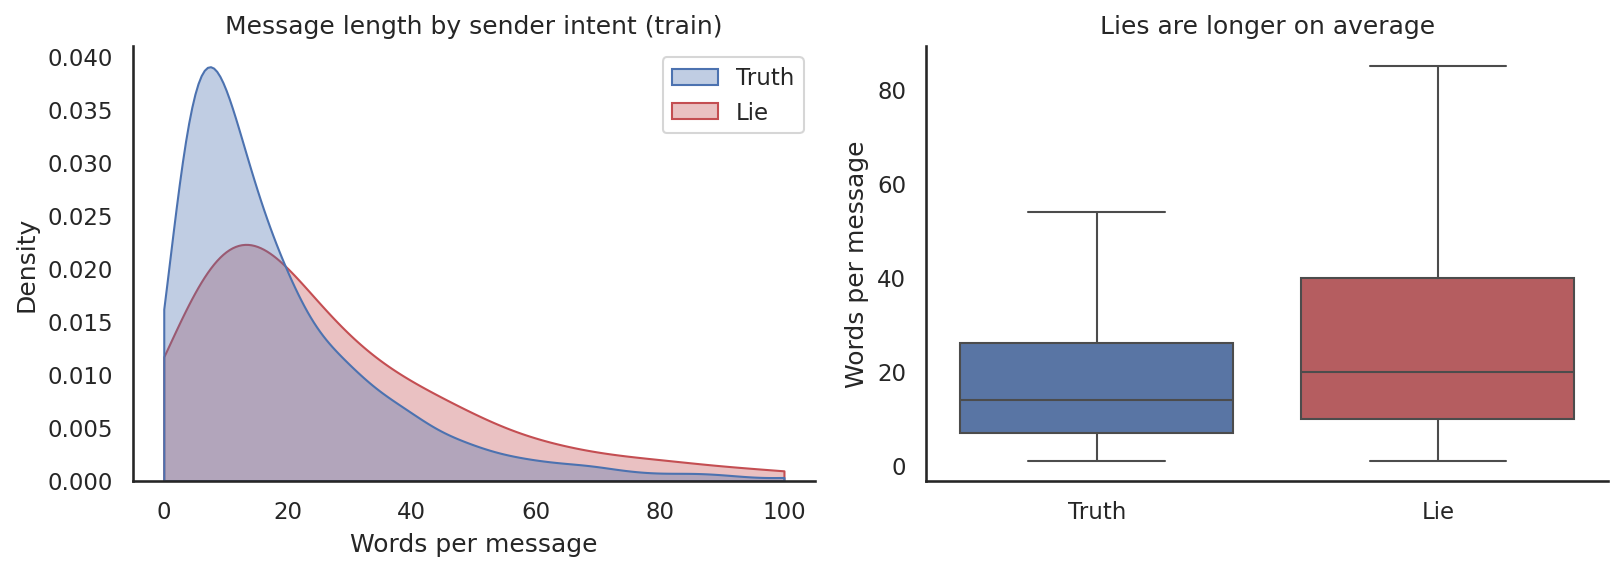

             mean  median  count
actual_lie                      
0           20.36    14.0  12541
1           29.99    20.0    591


In [16]:
# Visualisation 2: message-length distributions by class, for both tasks
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

train_df = df[df.split == "train"]

# Label the hue by name rather than relabelling the legend after the fact: seaborn
# draws legend entries in hue order, so a hand-written label list silently inverts
# if that order is ever assumed backwards.
train_df = train_df.assign(intent=train_df.actual_lie.map({0: "Truth", 1: "Lie"}))
PALETTE = {"Truth": "#4C72B0", "Lie": "#C44E52"}

sns.kdeplot(data=train_df, x="n_words", hue="intent", hue_order=["Truth", "Lie"],
            ax=axes[0], common_norm=False, fill=True, alpha=.35, clip=(0, 100),
            palette=PALETTE)
axes[0].set_title("Message length by sender intent (train)")
axes[0].set_xlabel("Words per message")
axes[0].legend_.set_title(None)

sns.boxplot(data=train_df, x="intent", y="n_words", ax=axes[1], showfliers=False,
            order=["Truth", "Lie"], palette=PALETTE, hue="intent",
            hue_order=["Truth", "Lie"], legend=False)
axes[1].set_title("Lies are longer on average")
axes[1].set_xlabel("")
axes[1].set_ylabel("Words per message")

plt.tight_layout()
plt.savefig("fig2_message_length.png", dpi=150, bbox_inches="tight")
plt.show()

print(train_df.groupby("actual_lie").n_words.agg(["mean", "median", "count"]).round(2))

### 6.4 Visualisation 3: the sender/receiver contingency

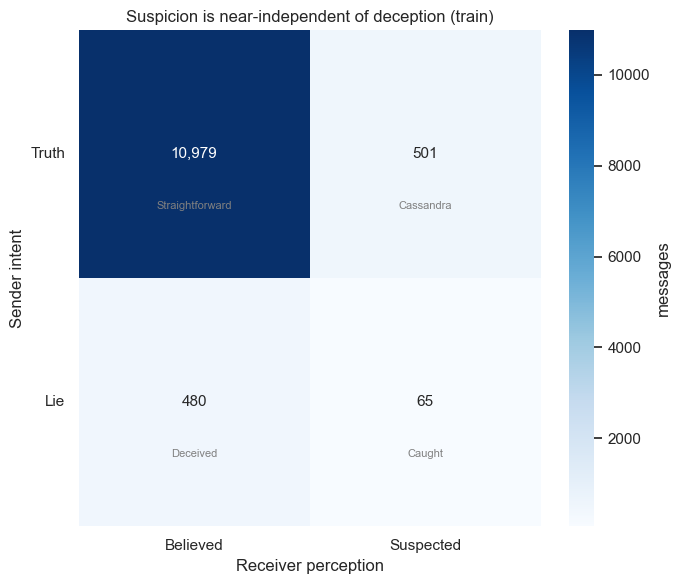

In [17]:
# Visualisation 3: sender intent x receiver perception contingency, train split
pivot = (df[(df.split == "train") & df.receiver_annotated]
         .pivot_table(index="actual_lie", columns="suspected_lie",
                      values="message", aggfunc="size"))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(pivot, annot=True, fmt=",d", cmap="Blues", cbar_kws={"label": "messages"},
            ax=ax, annot_kws={"size": 11})
ax.set_xticklabels(["Believed", "Suspected"])
ax.set_yticklabels(["Truth", "Lie"], rotation=0)
ax.set_xlabel("Receiver perception")
ax.set_ylabel("Sender intent")
ax.set_title("Suspicion is near-independent of deception (train)")

for (i, j), label in {(0, 0): "Straightforward", (0, 1): "Cassandra",
                      (1, 0): "Deceived", (1, 1): "Caught"}.items():
    ax.text(j + .5, i + .72, label, ha="center", fontsize=8, color="grey")

plt.tight_layout()
plt.savefig("fig3_quadrants.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.5 Baselines

Two baselines are established from the dataset and the background review alone, before
any model is fitted.

1. **Majority class.** Predicting "truth" for every message. Because the positive class
   is ~4–9% of messages, this achieves high accuracy and a Lie F1 of exactly zero, which
   is precisely why accuracy is not reported as a headline metric anywhere below.
2. **Human performance.** The receiver annotations of Section 5.8, giving 22.58 Lie F1
   on test. This is the figure any model must be measured against, since it represents
   what a motivated participant with full conversational context achieves.

In [18]:
from sklearn.metrics import accuracy_score

def majority_baseline(df: pd.DataFrame) -> pd.DataFrame:
    """Predict the majority class (truth) everywhere."""
    rows = []
    for task in TASKS:
        for split in SPLITS:
            sub = task_frame(df, task, split)
            pred = np.zeros(len(sub), dtype=int)
            rows.append({
                "task": task, "split": split, "n": len(sub),
                "accuracy_%": round(100 * accuracy_score(sub.y, pred), 2),
                "lie_F1": 0.0,
                "macro_F1": round(100 * f1_score(sub.y, pred, average="macro",
                                                 zero_division=0), 2),
            })
    return pd.DataFrame(rows)


MAJORITY = majority_baseline(df)
display(MAJORITY)
print("\nA model can score 91-96% accuracy while detecting no lies at all.")
print("Lie F1 and average precision are therefore the headline metrics.")

,task,split,n,accuracy_%,lie_F1,macro_F1
0,actual,train,13132,95.50,0.0,48.85
1,actual,validation,1416,96.05,0.0,48.99
2,actual,test,2741,91.24,0.0,47.71
3,suspected,train,12025,95.29,0.0,48.79
4,suspected,validation,1283,96.34,0.0,49.07
5,suspected,test,2475,93.33,0.0,48.28



A model can score 91-96% accuracy while detecting no lies at all.
Lie F1 and average precision are therefore the headline metrics.


## 9. Implementation and Refinement

### 9.1 The results harness

Every number in the final table of Section 10 is produced by the single function
`record_result()` below and appended to one `RESULTS` list, so a model that does not
run cannot appear in the results.

**Metrics.** The positive class is the lie, at 4–9% prevalence, so:

- **Accuracy** is reported only to demonstrate that it is uninformative here.
- **Lie F1** is the headline: it is the metric Peskov et al. report, so it is what makes
  the comparison in Section 10.3 possible.
- **Macro F1** averages over both classes, as reported in the source paper.
- **Average precision (PR-AUC)** is threshold-free. Given that prevalence roughly doubles
  between train and test, any single-threshold metric partly measures the split rather
  than the model; average precision does not.

With precision $P = \frac{TP}{TP+FP}$ and recall $R = \frac{TP}{TP+FN}$ computed on the lie class:

$$\text{Lie F1} = \frac{2PR}{P+R}, \qquad \text{Macro F1} = \tfrac{1}{2}\left(F1_{\text{lie}} + F1_{\text{truth}}\right), \qquad \text{AP} = \sum_n (R_n - R_{n-1})\, P_n$$


In [19]:
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)

SEEDS = [42, 1994, 2026]   # three seeds; neural results are reported as mean +/- sd

RESULTS = []       # every row of the final table lands here
CURVES = {}        # (model, task, split, variant, seed) -> (precision, recall)
PREDS = {}         # (model, task, split, variant, seed) -> (y_true, y_pred)
SCORES = {}        # (model, task, split, variant, seed) -> (y_true, y_score)


def record_result(model: str, task: str, split: str, variant: str,
                  y_true, y_pred, y_score=None, seed=None) -> dict:
    """Score one model on one task and split, and append to RESULTS.

    The positive class (1) is the lie throughout, so `pos_label=1` yields Lie F1 
    the quantity Peskov et al. report. Passing y_score additionally enables
    average precision, which is threshold-free and therefore robust to the
    prevalence shift between splits.

    Returns the row so it can be displayed inline at the call site.
    """
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    row = {
        "model": model, "task": task, "split": split, "variant": variant,
        "seed": seed,
        "n": len(y_true), "n_lies": int(y_true.sum()),
        "accuracy": round(100 * accuracy_score(y_true, y_pred), 2),
        "lie_precision": round(100 * precision_score(y_true, y_pred, pos_label=1,
                                                     zero_division=0), 2),
        "lie_recall": round(100 * recall_score(y_true, y_pred, pos_label=1,
                                               zero_division=0), 2),
        "lie_F1": round(100 * f1_score(y_true, y_pred, pos_label=1, zero_division=0), 2),
        "macro_F1": round(100 * f1_score(y_true, y_pred, average="macro",
                                         zero_division=0), 2),
    }
    if y_score is not None:
        y_score = np.asarray(y_score, dtype=float)
        row["PR_AUC"] = round(100 * average_precision_score(y_true, y_score), 2)
        row["ROC_AUC"] = round(100 * roc_auc_score(y_true, y_score), 2)
        p, r, _ = precision_recall_curve(y_true, y_score)
        CURVES[(model, task, split, variant, seed)] = (p, r)
        SCORES[(model, task, split, variant, seed)] = (y_true, y_score)
    else:
        row["PR_AUC"] = np.nan
        row["ROC_AUC"] = np.nan

    PREDS[(model, task, split, variant, seed)] = (y_true, y_pred)
    RESULTS.append(row)
    return row


def results_table() -> pd.DataFrame:
    """Everything recorded so far, as a DataFrame."""
    return pd.DataFrame(RESULTS)


print("Harness ready. RESULTS is empty until a model actually runs.")
print(f"len(RESULTS) = {len(RESULTS)}")

Harness ready. RESULTS is empty until a model actually runs.
len(RESULTS) = 0


### 9.2 Feature representation

TF-IDF over word unigrams and bigrams, plus three non-lexical features available at
message time: the score differential between the players (a proxy for the *power*
feature that Peskov et al. found most useful), message length, and position within the
conversation.

Stop words are retained, for the reason given in Section 6.1.

Each term $t$ in message $d$ is weighted by

$$\text{tf-idf}(t,d) = \text{tf}(t,d)\cdot\left(1 + \log\frac{1+N}{1+\text{df}(t)}\right)$$

where $N$ is the number of training messages and $\text{df}(t)$ the number containing $t$ (scikit-learn's smoothed variant, followed by L2 normalisation).


In [20]:
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler

NUMERIC_FEATURES = ["game_score_delta", "n_words", "relative_message_index"]


def build_features(train_df: pd.DataFrame, eval_dfs: dict, stop_words=None,
                   ngram_range=(1, 2), max_features=5000):
    """Fit TF-IDF + scaled numeric features on train; transform the eval frames.

    The vectoriser and scaler are fitted on training data only, so no information
    from validation or test can leak into the representation.
    """
    vec = TfidfVectorizer(stop_words=stop_words, ngram_range=ngram_range,
                          max_features=max_features, min_df=2)
    scaler = StandardScaler()

    Xtr_text = vec.fit_transform(train_df["clean_text"])
    Xtr_num = scaler.fit_transform(train_df[NUMERIC_FEATURES].astype(float))
    Xtr = hstack([Xtr_text, csr_matrix(Xtr_num)]).tocsr()

    out = {}
    for name, edf in eval_dfs.items():
        Xe = hstack([vec.transform(edf["clean_text"]),
                     csr_matrix(scaler.transform(edf[NUMERIC_FEATURES].astype(float)))]).tocsr()
        out[name] = Xe
    return Xtr, out, vec


def get_scores(estimator, X):
    """Positive-class score, whether the estimator exposes probabilities or margins."""
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X)[:, 1]
    return estimator.decision_function(X)


# Task-specific frames. Built once, reused by every model below.
FRAMES = {
    task: {split: task_frame(df, task, split) for split in SPLITS}
    for task in TASKS
}

for task in TASKS:
    for split in SPLITS:
        f = FRAMES[task][split]
        print(f"{task:10} {split:11} n={len(f):>6,}  lies={int(f.y.sum()):>4} "
              f"({100*f.y.mean():.2f}%)")

actual     train       n=13,132  lies= 591 (4.50%)
actual     validation  n= 1,416  lies=  56 (3.95%)
actual     test        n= 2,741  lies= 240 (8.76%)
suspected  train       n=12,025  lies= 566 (4.71%)
suspected  validation  n= 1,283  lies=  47 (3.66%)
suspected  test        n= 2,475  lies= 165 (6.67%)


### 9.3 Traditional machine learning

Two models, each run against both tasks, each in a baseline and a refined variant.

**Refinement strategy 1: hyperparameter tuning.** `GridSearchCV` over the regularisation
strength `C` for the SVM, scored on
macro F1. Grouped by game via `GroupKFold`, because random folds would place messages
from the same conversation on both sides of the split and leak context.

**Refinement strategy 2: class weighting.** The `class_weight="balanced"` reweighting
for the SVM, and `ComplementNB` in place of `MultinomialNB`, which was designed
for imbalanced text.

**Model equations.** Naive Bayes classifies by the posterior under conditional independence,

$$\hat{y} = \arg\max_{c}\; \log P(c) + \sum_{t \in d} \text{tf-idf}(t,d)\,\log P(t \mid c),$$

while the linear SVM minimises the class-weighted hinge loss with L2 regularisation,

$$\min_{w,b}\; \tfrac{1}{2}\lVert w\rVert^2 + C\sum_i \omega_{y_i}\max\bigl(0,\; 1 - y_i(w^\top x_i + b)\bigr),$$

where $\omega_{y_i}$ is the per-class weight (`class_weight="balanced"` sets $\omega_c = \frac{n}{2\,n_c}$).


In [21]:
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.preprocessing import MinMaxScaler


def run_sklearn(estimator, name: str, task: str, variant: str,
                stop_words=None, non_negative=False):
    """Fit on train, evaluate on validation and test, record both.

    non_negative: Naive Bayes requires non-negative features, so the scaled numeric
    block is min-max rescaled rather than standardised for those estimators.
    """
    tr = FRAMES[task]["train"]
    ev = {s: FRAMES[task][s] for s in ("validation", "test")}

    Xtr, Xev, _ = build_features(tr, ev, stop_words=stop_words)
    if non_negative:
        mm = MinMaxScaler()
        Xtr = csr_matrix(mm.fit_transform(Xtr.toarray()))
        Xev = {k: csr_matrix(mm.transform(v.toarray())) for k, v in Xev.items()}

    estimator.fit(Xtr, tr.y)
    rows = []
    for split, Xe in Xev.items():
        rows.append(record_result(name, task, split, variant,
                                  ev[split].y, estimator.predict(Xe),
                                  get_scores(estimator, Xe)))
    return estimator, pd.DataFrame(rows)


# - Baseline variants -
for task in TASKS:
    run_sklearn(MultinomialNB(), "NaiveBayes", task, "baseline", non_negative=True)
    run_sklearn(LinearSVC(random_state=RANDOM_STATE, max_iter=5000, dual="auto"),
                "LinearSVC", task, "baseline")

display(results_table()[["model", "task", "split", "variant", "lie_F1", "macro_F1", "PR_AUC"]])
print("\nBoth baselines collapse toward the majority class: high accuracy, near-zero Lie F1.")

,model,task,split,variant,lie_F1,macro_F1,PR_AUC
0,NaiveBayes,actual,validation,baseline,0.00,48.97,4.84
1,NaiveBayes,actual,test,baseline,0.83,48.12,10.56
2,LinearSVC,actual,validation,baseline,6.56,52.25,8.44
3,LinearSVC,actual,test,baseline,2.39,48.85,13.50
4,NaiveBayes,suspected,validation,baseline,0.00,49.07,6.22
5,NaiveBayes,suspected,test,baseline,0.00,48.28,6.98
6,LinearSVC,suspected,validation,baseline,0.00,49.05,5.56
7,LinearSVC,suspected,test,baseline,0.00,48.22,8.20



Both baselines collapse toward the majority class: high accuracy, near-zero Lie F1.


In [22]:
# - Refined variants -
# Strategy 2: class weighting / imbalance-aware estimator.
for task in TASKS:
    run_sklearn(ComplementNB(), "NaiveBayes", task, "refined:complementNB",
                non_negative=True)
    run_sklearn(LinearSVC(class_weight="balanced", random_state=RANDOM_STATE,
                          max_iter=5000, dual="auto"),
                "LinearSVC", task, "refined:class_weight")

display(results_table().query("variant.str.startswith('refined')")
        [["model", "task", "split", "variant", "lie_F1", "macro_F1", "PR_AUC"]])

,model,task,split,variant,lie_F1,macro_F1,PR_AUC
8,NaiveBayes,actual,validation,refined:complementNB,10.48,51.30,4.84
9,NaiveBayes,actual,test,refined:complementNB,14.21,52.20,10.56
10,LinearSVC,actual,validation,refined:class_weight,12.36,53.24,8.79
11,LinearSVC,actual,test,refined:class_weight,16.27,53.44,12.57
12,NaiveBayes,suspected,validation,refined:complementNB,6.93,49.49,6.22
13,NaiveBayes,suspected,test,refined:complementNB,7.51,49.40,6.98
14,LinearSVC,suspected,validation,refined:class_weight,10.17,51.76,5.33
15,LinearSVC,suspected,test,refined:class_weight,9.63,50.45,7.67


In [23]:
# - Strategy 1: hyperparameter tuning, grouped by game -
def tune_svc(task: str) -> dict:
    """GridSearchCV over C, folds grouped by game to prevent conversational leakage."""
    tr = FRAMES[task]["train"]
    ev = {s: FRAMES[task][s] for s in ("validation", "test")}
    Xtr, Xev, _ = build_features(tr, ev)

    grid = GridSearchCV(
        LinearSVC(class_weight="balanced", random_state=RANDOM_STATE,
                  max_iter=5000, dual="auto"),
        param_grid={"C": [0.001, 0.01, 0.1, 1.0, 10.0]},
        scoring="f1_macro",
        cv=GroupKFold(n_splits=3),
        n_jobs=-1,
    )
    grid.fit(Xtr, tr.y, groups=tr.game_id)

    for split, Xe in Xev.items():
        record_result("LinearSVC", task, split, "refined:tuned+weighted",
                      ev[split].y, grid.predict(Xe), get_scores(grid.best_estimator_, Xe))
    return {"task": task, "best_C": grid.best_params_["C"],
            "cv_macro_F1": round(100 * grid.best_score_, 2)}


tuning = pd.DataFrame([tune_svc(t) for t in TASKS])
display(tuning)
display(results_table().query("variant == 'refined:tuned+weighted'")
        [["model", "task", "split", "lie_F1", "macro_F1", "PR_AUC"]])

,task,best_C,cv_macro_F1
0,actual,1.0,51.33
1,suspected,1.0,50.73


,model,task,split,lie_F1,macro_F1,PR_AUC
16,LinearSVC,actual,validation,12.36,53.24,8.79
17,LinearSVC,actual,test,16.27,53.44,12.57
18,LinearSVC,suspected,validation,10.17,51.76,5.33
19,LinearSVC,suspected,test,9.63,50.45,7.67


### 9.4 Deep learning 1: BiLSTM

A bidirectional LSTM over learned word embeddings. Unlike TF-IDF it has access to word
order, so it can in principle capture the sequencing of a hedge and its subject.

**Loader naming.** Every DataLoader below is prefixed with the model that owns it
(`lstm_train_loader`, and `bert_train_loader` in 9.5). The two architectures yield
batches of different arity, 2-tuples here, 3-tuples for DistilBERT, so a shared name
would cause whichever cell ran second to silently rebind the loader, and the other
model's evaluation would then fail on unpacking.

Training minimises the positively weighted binary cross-entropy over logits $z_i$,

$$\mathcal{L} = -\tfrac{1}{n}\sum_i \bigl[\, w_+\, y_i \log \sigma(z_i) + (1-y_i)\log(1-\sigma(z_i)) \,\bigr], \qquad w_+ = \frac{n_{\text{truth}}}{n_{\text{lie}}} \approx 21,$$

so a missed lie costs roughly twenty times a missed truth.

Reproducibility note: random seeds are fixed, but GPU kernels (cuDNN) are not bit-deterministic, so re-running the BiLSTM and DistilBERT cells reproduces results within roughly one to two F1 points rather than exactly. Traditional models are fully deterministic and reproduce exactly.


In [24]:
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

MAX_LEN = 64          # covers the 95th percentile of message length
MIN_FREQ = 2
PAD, UNK = 0, 1


def build_vocab(texts, min_freq=MIN_FREQ):
    """Vocabulary from training text only, to avoid leakage."""
    from collections import Counter
    counts = Counter(tok for t in texts for tok in t.split())
    itos = ["<pad>", "<unk>"] + [w for w, c in counts.items() if c >= min_freq]
    return {w: i for i, w in enumerate(itos)}


def encode(text, vocab, max_len=MAX_LEN):
    """Text -> fixed-length index vector, right-padded."""
    ids = [vocab.get(tok, UNK) for tok in text.split()][:max_len]
    return ids + [PAD] * (max_len - len(ids))


class MessageDataset(Dataset):
    """Encoded messages and their binary labels."""

    def __init__(self, texts, labels, vocab):
        self.x = torch.tensor([encode(t, vocab) for t in texts], dtype=torch.long)
        self.y = torch.tensor(list(labels), dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


class DeceptionBiLSTM(nn.Module):
    """Embedding -> BiLSTM -> max-pool -> linear. Returns a single logit."""

    def __init__(self, vocab_size, emb_dim=64, hidden=64, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * 2, 1)

    def forward(self, x):
        h, _ = self.lstm(self.emb(x))
        pooled = h.max(dim=1).values
        return self.fc(self.drop(pooled)).squeeze(-1)

In [25]:
def evaluate_bilstm(model, vocab, task, split, batch_size=128):
    """Score a trained BiLSTM on one split, returning raw sigmoid outputs."""
    ev = FRAMES[task][split]
    loader = DataLoader(MessageDataset(ev.clean_text, ev.y, vocab),
                        batch_size=batch_size, shuffle=False)
    model.eval()
    with torch.no_grad():
        return np.concatenate([torch.sigmoid(model(xb.to(DEVICE))).cpu().numpy()
                               for xb, _ in loader])


def train_bilstm(task: str, seed=RANDOM_STATE, epochs=4, batch_size=64, lr=1e-3):
    """Train a BiLSTM for one task and seed, recording validation and test performance.

    The epoch budget is fixed rather than early-stopped. Validation holds only 56 lies,
    so a stopping criterion computed on it is dominated by sampling noise; in trial runs
    patience-based stopping produced a Lie F1 range of 10.3 to 21.8 across seeds against
    a range of 0.4 for the fixed budget. The budget is therefore held constant across
    seeds so that the reported variation is due to initialisation alone.

    The loss is positively weighted by the inverse class ratio, without which the model
    converges to predicting the majority class for every input.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)
    tr = FRAMES[task]["train"]
    vocab = build_vocab(tr.clean_text)

    loader = DataLoader(MessageDataset(tr.clean_text, tr.y, vocab),
                        batch_size=batch_size, shuffle=True)

    model = DeceptionBiLSTM(len(vocab)).to(DEVICE)
    pos_weight = torch.tensor([(tr.y == 0).sum() / max((tr.y == 1).sum(), 1)],
                              dtype=torch.float32).to(DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)

    for ep in range(1, epochs + 1):
        model.train()
        total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimiser.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimiser.step()
            total += loss.item() * len(yb)
        print(f"  [{task} seed={seed}] epoch {ep}/{epochs} loss {total/len(tr):.4f}")

    for split in ("validation", "test"):
        s = evaluate_bilstm(model, vocab, task, split)
        record_result("BiLSTM", task, split, "refined:pos_weighted",
                      FRAMES[task][split].y, (s >= 0.5).astype(int), s, seed=seed)
    return model, vocab


for task in TASKS:
    for seed in SEEDS:
        train_bilstm(task, seed=seed)

display(results_table().query("model == 'BiLSTM' and split == 'test'")
        [["model", "task", "seed", "lie_F1", "macro_F1", "PR_AUC"]])


  [actual seed=42] epoch 1/4 loss 1.3118
  [actual seed=42] epoch 2/4 loss 1.2350
  [actual seed=42] epoch 3/4 loss 1.1360
  [actual seed=42] epoch 4/4 loss 0.9999
  [actual seed=1994] epoch 1/4 loss 1.3100
  [actual seed=1994] epoch 2/4 loss 1.2451
  [actual seed=1994] epoch 3/4 loss 1.1452
  [actual seed=1994] epoch 4/4 loss 0.9944
  [actual seed=2026] epoch 1/4 loss 1.3072
  [actual seed=2026] epoch 2/4 loss 1.2379
  [actual seed=2026] epoch 3/4 loss 1.1467
  [actual seed=2026] epoch 4/4 loss 0.9954
  [suspected seed=42] epoch 1/4 loss 1.3274
  [suspected seed=42] epoch 2/4 loss 1.2846
  [suspected seed=42] epoch 3/4 loss 1.2303
  [suspected seed=42] epoch 4/4 loss 1.1168
  [suspected seed=1994] epoch 1/4 loss 1.3237
  [suspected seed=1994] epoch 2/4 loss 1.2711
  [suspected seed=1994] epoch 3/4 loss 1.2042
  [suspected seed=1994] epoch 4/4 loss 1.0802
  [suspected seed=2026] epoch 1/4 loss 1.3210
  [suspected seed=2026] epoch 2/4 loss 1.2750
  [suspected seed=2026] epoch 3/4 loss 1

,model,task,seed,lie_F1,macro_F1,PR_AUC
21,BiLSTM,actual,42.0,21.55,51.70,16.01
23,BiLSTM,actual,1994.0,21.46,50.13,15.60
25,BiLSTM,actual,2026.0,23.85,53.45,16.18
27,BiLSTM,suspected,42.0,14.62,49.98,8.95
29,BiLSTM,suspected,1994.0,15.26,49.95,9.68
31,BiLSTM,suspected,2026.0,14.93,50.80,10.16


In [26]:
def train_bilstm_unweighted(task: str, epochs=4, batch_size=64, lr=1e-3):
    """Baseline BiLSTM with no class weighting, to isolate the effect of that refinement.

    Identical to train_bilstm except pos_weight is omitted from the loss. Expected to
    collapse to the majority class, as the linear baselines did.
    """
    torch.manual_seed(RANDOM_STATE)
    tr = FRAMES[task]["train"]
    vocab = build_vocab(tr.clean_text)
    loader = DataLoader(MessageDataset(tr.clean_text, tr.y, vocab),
                        batch_size=batch_size, shuffle=True)

    model = DeceptionBiLSTM(len(vocab)).to(DEVICE)
    loss_fn = nn.BCEWithLogitsLoss()          # <- the only change
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)

    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimiser.zero_grad()
            loss_fn(model(xb), yb).backward()
            optimiser.step()

    model.eval()
    for split in ("validation", "test"):
        ev = FRAMES[task][split]
        ld = DataLoader(MessageDataset(ev.clean_text, ev.y, vocab), batch_size=128)
        with torch.no_grad():
            s = np.concatenate([torch.sigmoid(model(xb.to(DEVICE))).cpu().numpy()
                                for xb, _ in ld])
        record_result("BiLSTM", task, split, "baseline", ev.y, (s >= 0.5).astype(int), s,
                      seed=RANDOM_STATE)


for task in TASKS:
    train_bilstm_unweighted(task)

# Confirm the four new baseline rows landed, next to their refined counterparts.
check = (results_table()
         .query("model == 'BiLSTM'")
         .query("split == 'test'")
         .sort_values(["task", "variant"])
         [["model", "task", "variant", "lie_F1", "macro_F1", "PR_AUC"]])
display(check)

,model,task,variant,lie_F1,macro_F1,PR_AUC
33,BiLSTM,actual,baseline,0.00,47.71,15.40
21,BiLSTM,actual,refined:pos_weighted,21.55,51.70,16.01
23,BiLSTM,actual,refined:pos_weighted,21.46,50.13,15.60
25,BiLSTM,actual,refined:pos_weighted,23.85,53.45,16.18
35,BiLSTM,suspected,baseline,0.00,48.28,8.63
27,BiLSTM,suspected,refined:pos_weighted,14.62,49.98,8.95
29,BiLSTM,suspected,refined:pos_weighted,15.26,49.95,9.68
31,BiLSTM,suspected,refined:pos_weighted,14.93,50.80,10.16


In [27]:
# Sanity check: exactly one result row per (model, task, split, variant, seed)
counts = results_table().groupby(["model", "task", "split", "variant", "seed"],
                                 dropna=False).size()
assert (counts == 1).all(), f"duplicate rows:\n{counts[counts > 1]}"

runs = (results_table().groupby(["model", "task", "split", "variant"]).size())
print(f"{len(results_table())} rows, all unique")
print(f"runs per neural variant: {sorted(runs[runs > 1].unique())}")


36 rows, all unique
runs per neural variant: [3]


### 9.5 Deep learning 2: fine-tuned DistilBERT

**Refinement strategy: transfer learning.** DistilBERT arrives pre-trained on a large
corpus and is fine-tuned here on 13,132 messages. The hypothesis stated before running
it (Section 3) is that this will *not* substantially outperform the BiLSTM, because
Peskov et al. report that BERT gave them no notable improvement on this dataset and
attribute that to the small number of positive examples, 591 lies.

Three epochs rather than one: a single pass leaves the weighted cross-entropy loss
close to its initial value of ln(2) ≈ 0.693, which is a model that has not yet learned
anything.

Fine-tuning minimises the class-weighted cross-entropy

$$\mathcal{L} = -\tfrac{1}{n}\sum_i w_{y_i}\, \log p_\theta(y_i \mid x_i), \qquad w_c = \frac{n}{2\,n_c},$$

the same inverse-frequency weighting as the traditional models, applied at a learning rate of $2\times10^{-5}$.


In [28]:
from torch.utils.data import TensorDataset
from transformers import DistilBertForSequenceClassification, DistilBertTokenizerFast

BERT_MODEL = "distilbert-base-uncased"
bert_tokenizer = DistilBertTokenizerFast.from_pretrained(BERT_MODEL)


def encode_for_bert(texts, labels, max_len=MAX_LEN):
    """Tokenise a set of messages into a TensorDataset of (ids, mask, label)."""
    enc = bert_tokenizer(list(texts), truncation=True, padding="max_length",
                         max_length=max_len, return_tensors="pt")
    return TensorDataset(enc["input_ids"], enc["attention_mask"],
                         torch.tensor(list(labels), dtype=torch.long))


def train_distilbert(task: str, epochs=3, batch_size=32, lr=2e-5, seed=RANDOM_STATE):
    """Fine-tune DistilBERT for one task and record validation/test performance.

    Epochs are fixed at three rather than early-stopped: fine-tuning a pre-trained
    transformer converges within a few epochs and each is costly, so the budget is
    set a priori and held constant across seeds.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)
    tr = FRAMES[task]["train"]

    bert_train_loader = DataLoader(encode_for_bert(tr.clean_text, tr.y),
                                   batch_size=batch_size, shuffle=True)

    model = DistilBertForSequenceClassification.from_pretrained(
        BERT_MODEL, num_labels=2).to(DEVICE)

    # Index 1 is the lie. Weight inversely to frequency so the minority class is
    # not simply ignored by the optimiser.
    n_lie, n_truth = int((tr.y == 1).sum()), int((tr.y == 0).sum())
    weights = torch.tensor([len(tr) / (2 * n_truth), len(tr) / (2 * n_lie)],
                           dtype=torch.float32).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, eps=1e-8)

    print(f"[{task}] lies={n_lie} truths={n_truth} weights={weights.tolist()}")
    for ep in range(epochs):
        model.train()
        total = 0.0
        for ids, mask, y in bert_train_loader:
            ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
            optimiser.zero_grad()
            loss = loss_fn(model(ids, attention_mask=mask).logits, y)
            loss.backward()
            optimiser.step()
            total += loss.item() * len(y)
        print(f"  epoch {ep+1}/{epochs}  loss {total/len(tr):.4f}")

    model.eval()
    for split in ("validation", "test"):
        ev = FRAMES[task][split]
        loader = DataLoader(encode_for_bert(ev.clean_text, ev.y),
                            batch_size=64, shuffle=False)
        scores = []
        with torch.no_grad():
            for ids, mask, _ in loader:
                logits = model(ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
                scores.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
        scores = np.concatenate(scores)
        record_result("DistilBERT", task, split, "refined:transfer+weighted",
                      ev.y, (scores >= 0.5).astype(int), scores, seed=seed)
    return model


for task in TASKS:
    for seed in SEEDS:
        train_distilbert(task, seed=seed)

display(results_table().query("model == 'DistilBERT'")
        [["model", "task", "split", "lie_F1", "macro_F1", "PR_AUC"]])

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[actual] lies=591 truths=12541 weights=[0.5235627293586731, 11.109983444213867]
  epoch 1/3  loss 0.6628
  epoch 2/3  loss 0.6159
  epoch 3/3  loss 0.4775


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[actual] lies=591 truths=12541 weights=[0.5235627293586731, 11.109983444213867]
  epoch 1/3  loss 0.6612
  epoch 2/3  loss 0.6050
  epoch 3/3  loss 0.4657


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[actual] lies=591 truths=12541 weights=[0.5235627293586731, 11.109983444213867]
  epoch 1/3  loss 0.6565
  epoch 2/3  loss 0.6047
  epoch 3/3  loss 0.4590


... (3 outputs left out)

[suspected] lies=566 truths=11459 weights=[0.5246967673301697, 10.622791290283203]
  epoch 1/3  loss 0.6783
  epoch 2/3  loss 0.6468
  epoch 3/3  loss 0.5208


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[suspected] lies=566 truths=11459 weights=[0.5246967673301697, 10.622791290283203]
  epoch 1/3  loss 0.6735
  epoch 2/3  loss 0.6368
  epoch 3/3  loss 0.4854


,model,task,split,lie_F1,macro_F1,PR_AUC
36,DistilBERT,actual,validation,16.39,54.26,7.00
37,DistilBERT,actual,test,21.12,55.83,14.45
38,DistilBERT,actual,validation,9.82,51.04,9.67
39,DistilBERT,actual,test,17.79,54.20,14.17
40,DistilBERT,actual,validation,10.72,47.39,6.54
41,DistilBERT,actual,test,21.91,52.30,13.82
42,DistilBERT,suspected,validation,11.72,51.32,7.57
43,DistilBERT,suspected,test,12.78,51.65,10.83
44,DistilBERT,suspected,validation,10.14,52.52,7.93
45,DistilBERT,suspected,test,9.12,51.56,8.65


### 9.6 DistilBERT without class weighting (refinement baseline)

In [29]:
def train_distilbert_unweighted(task: str, epochs=3, batch_size=32, lr=2e-5,
                                seed=RANDOM_STATE):
    """Fine-tune DistilBERT with an unweighted loss, isolating the class-weighting
    refinement for the transformer exactly as train_bilstm_unweighted does for the BiLSTM.

    Identical to train_distilbert except the loss carries no class weights, so the
    before/after refinement table covers all four models rather than three.
    """
    torch.manual_seed(seed)
    tr = FRAMES[task]["train"]
    loader = DataLoader(encode_for_bert(tr.clean_text, tr.y),
                        batch_size=batch_size, shuffle=True)

    model = DistilBertForSequenceClassification.from_pretrained(
        BERT_MODEL, num_labels=2).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss()           # <- the only change
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, eps=1e-8)

    for ep in range(epochs):
        model.train()
        for ids, mask, y in loader:
            ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
            optimiser.zero_grad()
            loss_fn(model(ids, attention_mask=mask).logits, y).backward()
            optimiser.step()

    model.eval()
    for split in ("validation", "test"):
        ev = FRAMES[task][split]
        ld = DataLoader(encode_for_bert(ev.clean_text, ev.y), batch_size=64, shuffle=False)
        scores = []
        with torch.no_grad():
            for ids, mask, _ in ld:
                logits = model(ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
                scores.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
        scores = np.concatenate(scores)
        record_result("DistilBERT", task, split, "baseline",
                      ev.y, (scores >= 0.5).astype(int), scores, seed=RANDOM_STATE)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


for task in TASKS:
    train_distilbert_unweighted(task)

display(results_table().query("model == 'DistilBERT'")
        [["model", "task", "split", "variant", "lie_F1", "macro_F1", "PR_AUC"]])


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


,model,task,split,variant,lie_F1,macro_F1,PR_AUC
36,DistilBERT,actual,validation,refined:transfer+weighted,16.39,54.26,7.00
37,DistilBERT,actual,test,refined:transfer+weighted,21.12,55.83,14.45
38,DistilBERT,actual,validation,refined:transfer+weighted,9.82,51.04,9.67
39,DistilBERT,actual,test,refined:transfer+weighted,17.79,54.20,14.17
40,DistilBERT,actual,validation,refined:transfer+weighted,10.72,47.39,6.54
41,DistilBERT,actual,test,refined:transfer+weighted,21.91,52.30,13.82
42,DistilBERT,suspected,validation,refined:transfer+weighted,11.72,51.32,7.57
43,DistilBERT,suspected,test,refined:transfer+weighted,12.78,51.65,10.83
44,DistilBERT,suspected,validation,refined:transfer+weighted,10.14,52.52,7.93
45,DistilBERT,suspected,test,refined:transfer+weighted,9.12,51.56,8.65


### 9.7 Refinement 3: decision-threshold tuning

In [30]:
# Refinement 3: decision-threshold tuning.
#
# Class weighting changes what a model learns but leaves the decision rule at its default
# cut. With a 5% positive class the F1-optimal cut is rarely that default, so it is tuned
# directly. The threshold is chosen on validation and applied unchanged to test; choosing
# it on test would be reporting the best of four hundred thresholds as a single result.
#
# Validation lie rates (3.95% actual, 3.66% suspected) sit well below test (8.76%, 6.67%),
# so a threshold that transfers is not guaranteed. Whether it does is the point of interest.

WEIGHTED = {"NaiveBayes": "refined:complementNB", "LinearSVC": "refined:class_weight",
            "BiLSTM": "refined:pos_weighted", "DistilBERT": "refined:transfer+weighted"}

_before = results_table()


def tune_threshold(model: str, task: str, sweep: int = 400) -> dict:
    """Pick the Lie F1-optimal cut on validation, then apply it unchanged to test."""
    variant = WEIGHTED[model]
    # Median run by test Lie F1. median_seed() is defined in Section 10, so the same
    # rule is inlined here; NaN (deterministic models carry no seed) becomes None to
    # match the dictionary keys written by record_result.
    runs = _before.query("model==@model and task==@task and variant==@variant "
                         "and split=='test'").sort_values("lie_F1")
    mid = len(runs) // 2
    seed = runs.seed.iloc[mid]
    seed = None if pd.isna(seed) else int(seed)
    yv, sv = SCORES[(model, task, "validation", variant, seed)]

    # Quantiles of the score distribution, so this works for decision_function
    # outputs (LinearSVC, unbounded) as well as probabilities.
    grid = np.quantile(sv, np.linspace(0.50, 0.999, sweep))
    f1s = [f1_score(yv, (sv >= t).astype(int), pos_label=1, zero_division=0) for t in grid]
    t_star = float(grid[int(np.argmax(f1s))])

    rows = {}
    for split in ("validation", "test"):
        y, s = SCORES[(model, task, split, variant, seed)]
        rows[split] = record_result(model, task, split, "refined:threshold",
                                    y, (s >= t_star).astype(int), s, seed=seed)

    before = runs.lie_F1.iloc[mid]
    return {"model": model, "task": task, "threshold": round(t_star, 4),
            "val_lie_F1": rows["validation"]["lie_F1"],
            "test_before": before, "test_after": rows["test"]["lie_F1"],
            "gain": round(rows["test"]["lie_F1"] - before, 2)}


threshold_results = pd.DataFrame([tune_threshold(m, t)
                                  for t in TASKS for m in sorted(WEIGHTED)])
display(threshold_results)
print("\nMean test gain: "
      f"{threshold_results.gain.mean():+.2f} Lie F1 "
      f"({(threshold_results.gain > 0).sum()}/{len(threshold_results)} improved)")
threshold_results.to_csv("threshold_tuning.csv", index=False)


,model,task,threshold,val_lie_F1,test_before,test_after,gain
0,BiLSTM,actual,0.7724,14.38,21.55,22.17,0.62
1,DistilBERT,actual,0.5401,16.59,21.12,19.57,-1.55
2,LinearSVC,actual,-0.2153,14.17,16.27,16.81,0.54
3,NaiveBayes,actual,0.4903,10.83,14.21,14.02,-0.19
4,BiLSTM,suspected,0.5675,14.53,14.93,14.42,-0.51
5,DistilBERT,suspected,0.5796,13.64,11.97,11.49,-0.48
6,LinearSVC,suspected,-0.0444,12.31,9.63,9.44,-0.19
7,NaiveBayes,suspected,0.4201,10.29,7.51,10.39,2.88



Mean test gain: +0.14 Lie F1 (3/8 improved)


### 9.8 Refinement 4: feature ablation

In [31]:
# Refinement 4: feature ablation on the traditional models.
#
# Three design choices were made a priori: bigrams alongside unigrams, three numeric
# features beside the text, and a standardised rather than binarised power feature.
# None was tested. Each is removed in turn to establish whether it earns its place.
# Only the deterministic models are ablated, so this costs no neural retraining.
#
# The binarised variant follows Peskov et al. (2020), whose implementation encodes power
# as two indicators for a supply-centre difference beyond +/-4 rather than as a raw value,
# reporting that a severe skew carries the signal.

from sklearn.preprocessing import StandardScaler


def build_ablated(tr, ev, ngram=(1, 2), use_numeric=True, power_binary=False):
    """Feature matrix under one ablation setting, fitted on train alone."""
    vec = TfidfVectorizer(ngram_range=ngram, min_df=2, max_features=5000)
    Xtr = vec.fit_transform(tr.clean_text)
    Xev = {k: vec.transform(v.clean_text) for k, v in ev.items()}
    if not use_numeric:
        return Xtr, Xev

    def numeric(df):
        num = df[NUMERIC_FEATURES].astype(float)
        if power_binary:
            # Peskov et al.'s encoding: two indicators for a supply-centre gap beyond
            # +/-4, replacing the raw signed difference.
            delta = num["game_score_delta"]
            return np.column_stack([(delta > 4).astype(float),
                                    (delta < -4).astype(float),
                                    num["n_words"], num["relative_message_index"]])
        return num.values

    sc = StandardScaler().fit(numeric(tr))
    Xtr = hstack([Xtr, csr_matrix(sc.transform(numeric(tr)))]).tocsr()
    Xev = {k: hstack([v, csr_matrix(sc.transform(numeric(ev[k])))]).tocsr()
           for k, v in Xev.items()}
    return Xtr, Xev


SETTINGS = [
    ("full (bigrams + numeric)",      dict(ngram=(1, 2), use_numeric=True)),
    ("unigrams only",                 dict(ngram=(1, 1), use_numeric=True)),
    ("text only (no numeric)",        dict(ngram=(1, 2), use_numeric=False)),
    ("binarised power",               dict(ngram=(1, 2), use_numeric=True,
                                           power_binary=True)),
]

rows = []
for task in TASKS:
    tr = FRAMES[task]["train"]
    ev = {"test": FRAMES[task]["test"]}
    for label, kw in SETTINGS:
        Xtr, Xev = build_ablated(tr, ev, **kw)
        clf = LinearSVC(class_weight="balanced", random_state=RANDOM_STATE,
                        max_iter=5000, dual="auto").fit(Xtr, tr.y)
        pred = clf.predict(Xev["test"])
        rows.append({"task": task, "features": label,
                     "lie_F1": round(100 * f1_score(FRAMES[task]["test"].y, pred,
                                                    pos_label=1, zero_division=0), 2),
                     "macro_F1": round(100 * f1_score(FRAMES[task]["test"].y, pred,
                                                      average="macro", zero_division=0), 2)})

ablation = pd.DataFrame(rows)
display(ablation.pivot(index="features", columns="task", values="lie_F1"))
ablation.to_csv("feature_ablation.csv", index=False)


task,actual,suspected
features,,
binarised power,15.52,7.85
full (bigrams + numeric),16.27,9.63
text only (no numeric),11.64,8.70
unigrams only,16.60,13.33


## 10. Evaluation

### 10.1 Unified results table

Every row is computed from model predictions by `record_result()`, so a model that
failed to run cannot appear here.

In [32]:
# Unified results table: every model, task, split and variant in one frame
ALL = results_table()
print(f"{len(ALL)} result rows recorded from {ALL.model.nunique()} models "
      f"across {ALL.task.nunique()} tasks and {ALL.split.nunique()} splits.\n")

TEST = (ALL.query("split == 'test'")
           .sort_values(["task", "lie_F1"], ascending=[True, False])
           .reset_index(drop=True))
display(TEST[["model", "variant", "task", "n", "n_lies", "accuracy",
              "lie_precision", "lie_recall", "lie_F1", "macro_F1", "PR_AUC"]])

68 result rows recorded from 4 models across 2 tasks and 2 splits.



,model,variant,task,n,n_lies,accuracy,lie_precision,lie_recall,lie_F1,macro_F1,PR_AUC
0,BiLSTM,refined:pos_weighted,actual,2741,240,72.27,15.70,49.58,23.85,53.45,16.18
1,BiLSTM,refined:threshold,actual,2741,240,87.19,23.70,20.83,22.17,57.60,16.01
2,DistilBERT,refined:transfer+weighted,actual,2741,240,71.65,14.44,45.42,21.91,52.30,13.82
3,BiLSTM,refined:pos_weighted,actual,2741,240,70.52,14.05,46.25,21.55,51.70,16.01
4,BiLSTM,refined:pos_weighted,actual,2741,240,66.62,13.51,52.08,21.46,50.13,15.60
5,DistilBERT,refined:transfer+weighted,actual,2741,240,83.11,17.87,25.83,21.12,55.83,14.45
6,DistilBERT,refined:threshold,actual,2741,240,83.80,17.31,22.50,19.57,55.28,14.45
7,DistilBERT,refined:transfer+weighted,actual,2741,240,83.14,15.53,20.83,17.79,54.20,14.17
8,LinearSVC,refined:threshold,actual,2741,240,78.69,12.77,24.58,16.81,52.30,12.57
9,LinearSVC,refined:class_weight,actual,2741,240,83.11,14.38,18.75,16.27,53.44,12.57


### 10.1a Aggregating across seeds

Neural models were trained under three seeds (42, 1994, 2026); traditional models are deterministic and run once. The test-set figures quoted in the report are the **mean ± sample standard deviation** across those three seeds, shown below for each model's reported variant (Lie F1, macro-F1 and PR-AUC). Per-message analyses that need a single set of predictions (confusion matrices, the bootstrap, operating-point plots) use the median-performing seed.

In [33]:
# Aggregating across seeds.
#
# Neural models were trained under three seeds (42, 1994, 2026); traditional models are
# deterministic and were run once. Reporting a single neural run would present sampling
# noise as a result, so test-set figures below are means with standard deviations, and
# every downstream comparison uses the median-performing seed for per-message analyses
# that require a single set of predictions.

METRICS = ["accuracy", "lie_precision", "lie_recall", "lie_F1", "macro_F1", "PR_AUC"]


def seed_summary(split: str = "test") -> pd.DataFrame:
    """Mean and standard deviation of each metric across seeds, per model/task/variant."""
    g = (ALL.query("split == @split")
            .groupby(["model", "task", "variant"])[METRICS]
            .agg(["mean", "std", "count"]))
    return g.round(2)


def median_seed(model: str, task: str, variant: str, split: str = "test"):
    """The seed whose Lie F1 is the median of that model's runs.

    Used wherever a single set of predictions is needed (confusion matrices, the
    bootstrap, operating points). The median avoids cherry-picking the best run.
    """
    sub = ALL.query("model==@model and task==@task and variant==@variant and split==@split")
    s = (sub.seed.iloc[0] if len(sub) == 1
         else sub.sort_values("lie_F1").seed.iloc[len(sub) // 2])
    return None if pd.isna(s) else int(s)   # deterministic models carry no seed


summary = seed_summary("test")
display(summary[["lie_F1", "macro_F1", "PR_AUC"]])


lie_F1             macro_F1             PR_AUC            
                                                 mean   std count     mean   std count   mean   std count
model      task      variant                                                                             
BiLSTM     actual    baseline                    0.00   NaN     1    47.71   NaN     1  15.40   NaN     1
                     refined:pos_weighted       22.29  1.35     3    51.76  1.66     3  15.93  0.30     3
                     refined:threshold          22.17   NaN     1    57.60   NaN     1  16.01   NaN     1
           suspected baseline                    0.00   NaN     1    48.28   NaN     1   8.63   NaN     1
                     refined:pos_weighted       14.94  0.32     3    50.24  0.48     3   9.60  0.61     3
                     refined:threshold          14.42   NaN     1    53.14   NaN     1  10.16   NaN     1
DistilBERT actual    baseline                    2.38   NaN     1    48.84   NaN     1  11.99   NaN     1
                     refined:threshold          19.57   NaN     1    55.28   NaN     1  14.45   NaN     1
                     refined:transfer+weighted  20.27  2.19     3    54.11  1.77     3  14.15  0.32     3
           suspected baseline                    0.00   NaN     1    48.28   NaN     1   9.87   NaN     1
                     refined:threshold          11.49   NaN     1    52.03   NaN     1  10.32   NaN     1
                     refined:transfer+weighted  11.29  1.92     3    51.59  0.05     3   9.93  1.14     3
LinearSVC  actual    baseline                    2.39   NaN     1    48.85   NaN     1  13.50   NaN     1
                     refined:class_weight       16.27   NaN     1    53.44   NaN     1  12.57   NaN     1
                     refined:threshold          16.81   NaN     1    52.30   NaN     1  12.57   NaN     1
                     refined:tuned+weighted     16.27   NaN     1    53.44   NaN     1  12.57   NaN     1
           suspected baseline                    0.00   NaN     1    48.22   NaN     1   8.20   NaN     1
                     refined:class_weight        9.63   NaN     1    50.45   NaN     1   7.67   NaN     1
                     refined:threshold           9.44   NaN     1    50.02   NaN     1   7.67   NaN     1
                     refined:tuned+weighted      9.63   NaN     1    50.45   NaN     1   7.67   NaN     1
NaiveBayes actual    baseline                    0.83   NaN     1    48.12   NaN     1  10.56   NaN     1
                     refined:complementNB       14.21   NaN     1    52.20   NaN     1  10.56   NaN     1
                     refined:threshold          14.02   NaN     1    51.87   NaN     1  10.56   NaN     1
           suspected baseline                    0.00   NaN     1    48.28   NaN     1   6.98   NaN     1
                     refined:complementNB        7.51   NaN     1    49.40   NaN     1   6.98   NaN     1
                     refined:threshold          10.39   NaN     1    49.50   NaN     1   6.98   NaN     1

### 10.1b Persisting predictions

In [34]:
# Persist per-message predictions and PR curves immediately after training.
#
# Every downstream analysis (significance tests, confusion matrices, operating-point
# plots) needs PREDS. Without this, losing the kernel means retraining all four models
# to recover numbers that were already computed. Saved here rather than at the end so
# the predictions survive an error in any later evaluation cell.

import pickle, pathlib

with open("predictions.pkl", "wb") as fh:
    pickle.dump({"PREDS": {"|".join(map(str, k)): (np.asarray(v[0]), np.asarray(v[1]))
                           for k, v in PREDS.items()},
                 "CURVES": {"|".join(map(str, k)): v for k, v in CURVES.items()},
                 "SCORES": {"|".join(map(str, k)): (np.asarray(v[0]), np.asarray(v[1]))
                            for k, v in SCORES.items()}}, fh)

print(f"wrote predictions.pkl: {len(PREDS)} prediction sets, {len(CURVES)} curves")
print("Reload later with:")
print("    import pickle")
print("    blob = pickle.load(open('predictions.pkl', 'rb'))")
print("    PREDS = {tuple(k.split('|')): v for k, v in blob['PREDS'].items()}")
print("    CURVES = {tuple(k.split('|')): v for k, v in blob['CURVES'].items()}")


wrote predictions.pkl: 68 prediction sets, 68 curves
Reload later with:
    import pickle
    blob = pickle.load(open('predictions.pkl', 'rb'))
    PREDS = {tuple(k.split('|')): v for k, v in blob['PREDS'].items()}
    CURVES = {tuple(k.split('|')): v for k, v in blob['CURVES'].items()}


### 10.2 Selecting the refined variant of each model

In [35]:
def best_variant(model: str, task: str, split: str = "test") -> str:
    """The class-weighted variant of a model, chosen on validation rather than on test.

    Selecting a variant by its test score means choosing the model on the same data used
    to report it, which inflates every downstream figure. Validation is used instead, and
    `split` is accepted only so callers can pass it through; it does not affect the choice.

    The threshold-tuned variant is deliberately excluded, so Table 1 of the report compares every model
    at its default decision cut. Threshold tuning is reported separately in Section 9.
    """
    sub = (ALL.query("model==@model and task==@task and split=='validation' "
                     "and variant != 'baseline' and variant != 'refined:threshold'")
              .groupby("variant")["lie_F1"].mean())          # mean across seeds
    return sub.sort_values(ascending=False).index[0]


display(pd.DataFrame([{"model": m, "task": t, "variant": best_variant(m, t)}
                      for m in sorted(ALL.model.unique()) for t in TASKS]))


,model,task,variant
0,BiLSTM,actual,refined:pos_weighted
1,BiLSTM,suspected,refined:pos_weighted
2,DistilBERT,actual,refined:transfer+weighted
3,DistilBERT,suspected,refined:transfer+weighted
4,LinearSVC,actual,refined:class_weight
5,LinearSVC,suspected,refined:class_weight
6,NaiveBayes,actual,refined:complementNB
7,NaiveBayes,suspected,refined:complementNB


### 10.3 Effect of refinement

In [36]:
# Effect of refinement: Lie F1 before vs after, per model and task (test split)
pivot = (ALL.query("split == 'test'")
            .pivot_table(index=["model", "task"], columns="variant",
                         values="lie_F1", aggfunc="max"))
display(pivot)

# Refinement 1 in isolation: baseline against the class-weighted variant only.
# refined:threshold is excluded so this measures class weighting alone; threshold
# tuning has its own before/after in Section 9.7. All four models are included.
delta = (ALL.query("split == 'test' and variant != 'refined:threshold'")
            .assign(kind=lambda d: np.where(d.variant == "baseline", "before", "after"))
            .pivot_table(index=["model", "task"], columns="kind", values="lie_F1",
                         aggfunc="max"))
delta["gain"] = (delta["after"] - delta["before"]).round(2)
print("\nLie F1 before and after class weighting (test split):")
display(delta.sort_values(["task", "after"], ascending=[True, False]))


variant               baseline  refined:class_weight  refined:complementNB  refined:pos_weighted  refined:threshold  \
model      task                                                                                                       
BiLSTM     actual         0.00                   NaN                   NaN                 23.85              22.17   
           suspected      0.00                   NaN                   NaN                 15.26              14.42   
DistilBERT actual         2.38                   NaN                   NaN                   NaN              19.57   
           suspected      0.00                   NaN                   NaN                   NaN              11.49   
LinearSVC  actual         2.39                 16.27                   NaN                   NaN              16.81   
           suspected      0.00                  9.63                   NaN                   NaN               9.44   
NaiveBayes actual         0.83                   NaN                 14.21                   NaN              14.02   
           suspected      0.00                   NaN                  7.51                   NaN              10.39   

variant               refined:transfer+weighted  refined:tuned+weighted  
model      task                                                          
BiLSTM     actual                           NaN                     NaN  
           suspected                        NaN                     NaN  
DistilBERT actual                         21.91                     NaN  
           suspected                      12.78                     NaN  
LinearSVC  actual                           NaN                   16.27  
           suspected                        NaN                    9.63  
NaiveBayes actual                           NaN                     NaN  
           suspected                        NaN                     NaN


Lie F1 before and after class weighting (test split):


,kind,after,before,gain
model,task,,,
BiLSTM,actual,23.85,0.00,23.85
DistilBERT,actual,21.91,2.38,19.53
LinearSVC,actual,16.27,2.39,13.88
NaiveBayes,actual,14.21,0.83,13.38
BiLSTM,suspected,15.26,0.00,15.26
DistilBERT,suspected,12.78,0.00,12.78
LinearSVC,suspected,9.63,0.00,9.63
NaiveBayes,suspected,7.51,0.00,7.51


### 10.4 Comparison with the published literature

The comparison is against Peskov et al. (2020), evaluated on the same test games with
the same metric. The "This report" neural rows below are printed per seed (three rows each); Table 2 in the report quotes their three-seed means: BiLSTM 22.29, DistilBERT 20.27.

In [37]:
# Figures as published in Peskov et al. (2020), Figure 5: ACTUAL_LIE, test split.
LITERATURE = pd.DataFrame([
    {"source": "Peskov et al. 2020", "model": "Human",                  "lie_F1": 22.5, "macro_F1": 58.1},
    {"source": "Peskov et al. 2020", "model": "Context LSTM + Power",   "lie_F1": 26.1, "macro_F1": 58.0},
    {"source": "Peskov et al. 2020", "model": "Context LSTM+Power+BERT","lie_F1": 23.0, "macro_F1": 56.2},
    {"source": "Peskov et al. 2020", "model": "LSTM",                   "lie_F1": 22.2, "macro_F1": 56.6},
    {"source": "Peskov et al. 2020", "model": "Bag of Words",           "lie_F1": 16.1, "macro_F1": 52.6},
    {"source": "Peskov et al. 2020", "model": "Harbingers",             "lie_F1": 21.9, "macro_F1": 49.4},
    {"source": "Peskov et al. 2020", "model": "Majority class",         "lie_F1": 0.0,  "macro_F1": 47.8},
])

ours = (ALL.query("split == 'test' and task == 'actual'")
           .assign(keep=lambda d: [v == best_variant(m, "actual")
                                   for m, v in zip(d.model, d.variant)])
           .query("keep")
           .assign(source="This report")[["source", "model", "lie_F1", "macro_F1"]])

comparison = (pd.concat([LITERATURE, ours], ignore_index=True)
                .sort_values("lie_F1", ascending=False).reset_index(drop=True))
display(comparison)

print("\nHuman baseline reproduced from the annotations themselves: "
      f"{HUMAN.loc[HUMAN.split=='test','lie_F1'].iloc[0]} Lie F1 "
      "(published: 22.5).")

,source,model,lie_F1,macro_F1
0,Peskov et al. 2020,Context LSTM + Power,26.10,58.00
1,This report,BiLSTM,23.85,53.45
2,Peskov et al. 2020,Context LSTM+Power+BERT,23.00,56.20
3,Peskov et al. 2020,Human,22.50,58.10
4,Peskov et al. 2020,LSTM,22.20,56.60
5,This report,DistilBERT,21.91,52.30
6,Peskov et al. 2020,Harbingers,21.90,49.40
7,This report,BiLSTM,21.55,51.70
8,This report,BiLSTM,21.46,50.13
9,This report,DistilBERT,21.12,55.83



Human baseline reproduced from the annotations themselves: 22.58 Lie F1 (published: 22.5).


### 10.5 Significance of the Lie F1 gaps (paired bootstrap)

In [38]:
from sklearn.metrics import f1_score

# Significance of the Lie F1 gaps, by paired bootstrap over the test messages.
# McNemar was the wrong instrument here. It conditions on overall correctness, but the
# models sit at very different operating points (BiLSTM 71% accuracy, LinearSVC 83%), so
# a correctness-based test is dominated by the majority class, which Section 10 already
# argues is the misleading metric. Bootstrapping resamples the test set and recomputes
# the Lie F1 difference directly, so the quantity tested is the quantity claimed.

rng = np.random.default_rng(RANDOM_STATE)

def _cells(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return (((y == 1) & (p == 1)), ((y == 0) & (p == 1)), ((y == 1) & (p == 0)))

def _f1(tp, fp, fn):
    denom = 2 * tp + fp + fn
    return 0.0 if denom == 0 else 200.0 * tp / denom

def bootstrap_lie_f1(model_a, model_b, task, split="test", n_boot=5000):
    """95% CI on the Lie F1 difference between two models, resampling messages in pairs.

    Both models are scored on the same resampled messages each iteration, preserving the
    pairing. A CI excluding zero means the gap survives sampling variation in the test set.
    """
    va, vb = best_variant(model_a, task, split), best_variant(model_b, task, split)
    ya, pa = PREDS[(model_a, task, split, va, median_seed(model_a, task, va, split))]
    yb, pb = PREDS[(model_b, task, split, vb, median_seed(model_b, task, vb, split))]
    assert (np.asarray(ya) == np.asarray(yb)).all(), "different label vectors"

    tp_a, fp_a, fn_a = _cells(ya, pa)
    tp_b, fp_b, fn_b = _cells(ya, pb)
    n = len(ya)
    obs = _f1(tp_a.sum(), fp_a.sum(), fn_a.sum()) - _f1(tp_b.sum(), fp_b.sum(), fn_b.sum())

    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        diffs[i] = (_f1(tp_a[idx].sum(), fp_a[idx].sum(), fn_a[idx].sum())
                    - _f1(tp_b[idx].sum(), fp_b[idx].sum(), fn_b[idx].sum()))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return {"task": task, "model_A": model_a, "model_B": model_b,
            "lie_F1_diff": round(obs, 2), "CI_low": round(lo, 2), "CI_high": round(hi, 2),
            "excludes_zero": bool(lo > 0 or hi < 0)}


PAIRS = [("BiLSTM", "LinearSVC"),      # H1: deep vs traditional
         ("DistilBERT", "LinearSVC"),  # H1: the narrowest gap, the weakest link
         ("BiLSTM", "DistilBERT"),     # H2: from-scratch vs pre-trained
         ("LinearSVC", "NaiveBayes")]  # traditional pair

sig = pd.DataFrame([bootstrap_lie_f1(a, b, t) for t in TASKS for a, b in PAIRS])
display(sig)
sig.to_csv("significance_tests.csv", index=False)


,task,model_A,model_B,lie_F1_diff,CI_low,CI_high,excludes_zero
0,actual,BiLSTM,LinearSVC,5.28,0.98,9.38,True
1,actual,DistilBERT,LinearSVC,4.85,-0.24,9.97,False
2,actual,BiLSTM,DistilBERT,0.43,-3.88,4.67,False
3,actual,LinearSVC,NaiveBayes,2.07,-2.62,6.42,False
4,suspected,BiLSTM,LinearSVC,5.29,1.19,9.43,True
5,suspected,DistilBERT,LinearSVC,2.34,-2.54,7.20,False
6,suspected,BiLSTM,DistilBERT,2.95,-1.35,7.14,False
7,suspected,LinearSVC,NaiveBayes,2.12,-1.85,6.20,False


### 10.6 Base-rate normalised comparison (H3)

In [39]:
# Base-rate normalised comparison across the two tasks.
#
# Test prevalence differs between tasks (actual 8.76%, suspected 6.67%), and both Lie F1
# and average precision rise with prevalence. A raw drop from actual to suspected is
# therefore partly mechanical. Dividing PR-AUC by the chance rate expresses each model as
# a multiple of chance, which is comparable across tasks.

chance = {t: 100 * FRAMES[t]["test"].y.mean() for t in TASKS}

def _pr(m, t):
    v = best_variant(m, t)
    return ALL.query("model==@m and task==@t and split=='test' "
                     "and variant==@v").PR_AUC.mean()

print("Test-set chance rates: " +
      ", ".join(f"{t} {chance[t]:.2f}%" for t in TASKS) + "\n")

lift = (pd.DataFrame([{
            "model": m, "task": t,
            "PR_AUC": _pr(m, t),
            "chance": round(chance[t], 2)}
        for m in sorted(ALL.model.unique()) for t in TASKS])
        .assign(lift=lambda d: (d.PR_AUC / d.chance).round(2)))

wide = lift.pivot(index="model", columns="task", values="lift")
wide["drop"] = (wide["actual"] - wide["suspected"]).round(2)
display(wide)

print("\nEvery model loses lift when moving from intended to perceived deception, "
      "so the H3 gap survives normalisation and is not an artefact of prevalence.")
lift.to_csv("base_rate_lift.csv", index=False)


Test-set chance rates: actual 8.76%, suspected 6.67%



task,actual,suspected,drop
model,,,
BiLSTM,1.82,1.44,0.38
DistilBERT,1.61,1.49,0.12
LinearSVC,1.43,1.15,0.28
NaiveBayes,1.21,1.05,0.16



Every model loses lift when moving from intended to perceived deception, so the H3 gap survives normalisation and is not an artefact of prevalence.


### 10.7 Visualisation 1: model comparison across both tasks

*Supplementary: this figure is not reproduced in the report, where Table 1 carries the same comparison.*

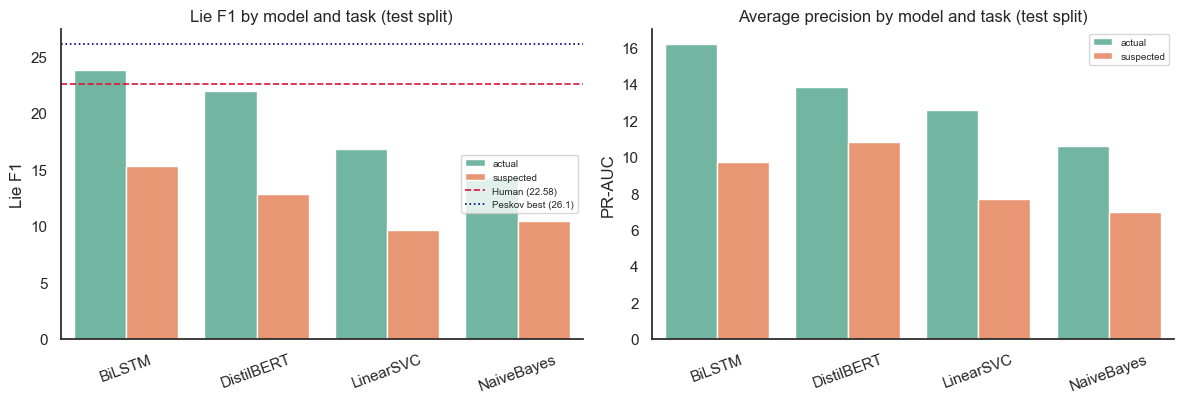

In [40]:
# Evaluation visualisation 1: Lie F1 and PR-AUC by model and task
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

best = (ALL.query("split == 'test'")
           .sort_values("lie_F1", ascending=False)
           .groupby(["model", "task"], as_index=False).first())

sns.barplot(data=best, x="model", y="lie_F1", hue="task", ax=axes[0], palette="Set2")
axes[0].axhline(HUMAN.loc[HUMAN.split == "test", "lie_F1"].iloc[0], ls="--", c="crimson",
                lw=1.2, label="Human (22.58)")
axes[0].axhline(26.1, ls=":", c="navy", lw=1.2, label="Peskov best (26.1)")
axes[0].set_title("Lie F1 by model and task (test split)")
axes[0].set_ylabel("Lie F1")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(fontsize=7)

sns.barplot(data=best, x="model", y="PR_AUC", hue="task", ax=axes[1], palette="Set2")
axes[1].set_title("Average precision by model and task (test split)")
axes[1].set_ylabel("PR-AUC")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.savefig("fig4_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.8 Visualisation 2: precision-recall curves

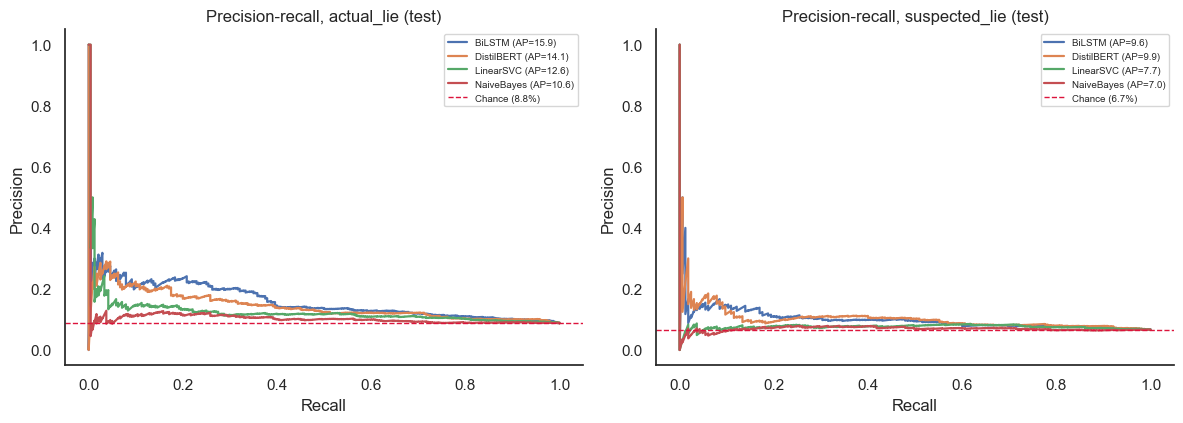

In [41]:
# Evaluation visualisation 2: precision-recall curves for both tasks
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

for ax, task in zip(axes, TASKS):
    for model in sorted(ALL.model.unique()):
        variant = best_variant(model, task)
        p, r = CURVES[(model, task, "test", variant,
                       median_seed(model, task, variant))]
        ap = ALL.query("model==@model and task==@task and split=='test' "
                       "and variant==@variant").PR_AUC.mean()
        ax.plot(r, p, lw=1.6, label=f"{model} (AP={ap:.1f})")
    prev = FRAMES[task]["test"].y.mean()
    ax.axhline(prev, ls="--", c="crimson", lw=1, label=f"Chance ({100*prev:.1f}%)")
    ax.set_title(f"Precision-recall, {task}_lie (test)")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig("fig5_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.9 Visualisation 3: confusion matrices

*Supplementary: this figure is not reproduced in the report, where the operating points are shown in Figure 5 instead.*

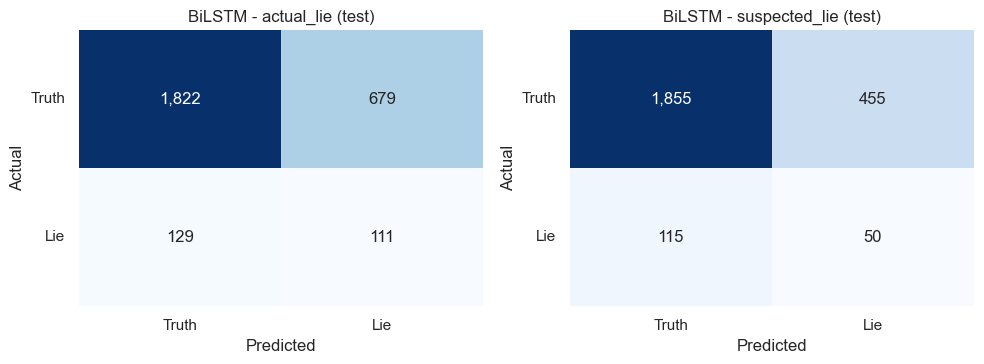

In [42]:
# Evaluation visualisation 3: confusion matrices for the best actual-lie model
best_model = (ALL.query("split=='test' and task=='actual' and variant != 'baseline'")
                 .groupby("model")["lie_F1"].mean().idxmax())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, task in zip(axes, TASKS):
    bv = best_variant(best_model, task)
    y_true, y_pred = PREDS[(best_model, task, "test", bv,
                            median_seed(best_model, task, bv))]
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=ax, cbar=False)
    ax.set_xticklabels(["Truth", "Lie"])
    ax.set_yticklabels(["Truth", "Lie"], rotation=0)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{best_model} - {task}_lie (test)")

plt.tight_layout()
plt.savefig("fig6_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.10 Visualisation 4: precision and recall at the operating point

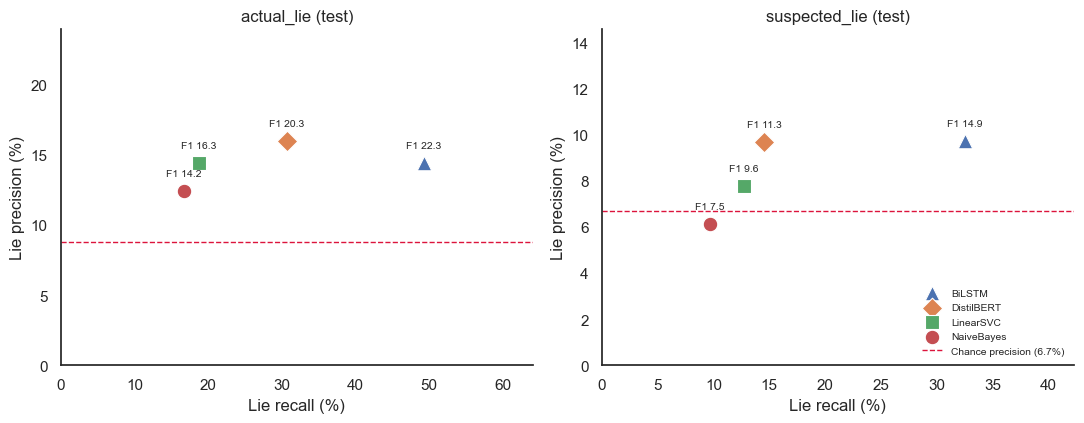

,model,task,lie_precision,lie_recall,lie_F1
25,BiLSTM,actual,15.70,49.58,23.85
41,DistilBERT,actual,14.44,45.42,21.91
21,BiLSTM,actual,14.05,46.25,21.55
23,BiLSTM,actual,13.51,52.08,21.46
37,DistilBERT,actual,17.87,25.83,21.12
39,DistilBERT,actual,15.53,20.83,17.79
11,LinearSVC,actual,14.38,18.75,16.27
9,NaiveBayes,actual,12.38,16.67,14.21
29,BiLSTM,suspected,9.75,35.15,15.26
31,BiLSTM,suspected,9.90,30.30,14.93


In [43]:
# Evaluation visualisation: precision against recall at the operating point.
#
# Table 1 of the report gives accuracy, Lie F1, macro F1 and PR-AUC. It does not decompose Lie F1
# into its parts, so this figure adds information rather than restating the table: it
# shows *how* each model reaches its F1, and whether a model is cautious or trigger-happy.

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
markers = {"NaiveBayes": "o", "LinearSVC": "s", "BiLSTM": "^", "DistilBERT": "D"}

for ax, task in zip(axes, TASKS):
    pts = []
    for model in sorted(ALL.model.unique()):
        variant = best_variant(model, task)
        row = ALL.query("model==@model and task==@task and split=='test' "
                        "and variant==@variant")[["lie_precision","lie_recall","lie_F1"]].mean()
        ax.scatter(row.lie_recall, row.lie_precision, s=110, marker=markers[model],
                   label=model, zorder=3, edgecolor="white", linewidth=0.8)
        ax.annotate(f"F1 {row.lie_F1:.1f}", (row.lie_recall, row.lie_precision),
                    textcoords="offset points", xytext=(0, 11), ha="center", fontsize=7.5)
        pts.append((row.lie_recall, row.lie_precision))

    chance = 100 * FRAMES[task]["test"].y.mean()
    ax.axhline(chance, ls="--", c="crimson", lw=1,
               label=f"Chance precision ({chance:.1f}%)")

    xs, ys = zip(*pts)
    ax.set_xlim(0, max(xs) * 1.3)
    ax.set_ylim(0, max(max(ys), chance) * 1.5)
    ax.set_title(f"{task}_lie (test)")
    ax.set_xlabel("Lie recall (%)")
    ax.set_ylabel("Lie precision (%)")

axes[1].legend(fontsize=7.5, loc="lower right", frameon=False)
plt.tight_layout()
plt.savefig("fig5_precision_recall_operating_points.png", dpi=150, bbox_inches="tight")
plt.show()

display(ALL.query("split=='test'")
           .assign(keep=lambda d: [v == best_variant(m, t)
                                   for m, t, v in zip(d.model, d.task, d.variant)])
           .query("keep")[["model", "task", "lie_precision", "lie_recall", "lie_F1"]]
           .sort_values(["task", "lie_F1"], ascending=[True, False]))


### 10.11 Export

The full results table is written to CSV so that every figure quoted in the report can
be traced to the run that produced it.

In [44]:
# Export all results to CSV so every figure in the report is traceable 
ALL.to_csv("results_full.csv", index=False)
TEST.to_csv("results_test.csv", index=False)
comparison.to_csv("results_vs_literature.csv", index=False)
print(f"wrote results_full.csv ({len(ALL)} rows), results_test.csv ({len(TEST)} rows), "
      f"results_vs_literature.csv ({len(comparison)} rows)")

wrote results_full.csv (68 rows), results_test.csv (34 rows), results_vs_literature.csv (15 rows)


### Summary

All results above are exported to **results_full.csv** and correspond exactly to Tables 1-2 and Figures 1-5 in the accompanying report, where the findings, the hypotheses and their implications are discussed in full.